<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-11/lab-067-atom-light-qubit.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 067. Physical qubits, an atom, a transmon and a spin

A qubit is any quantum system with two orthogonal states. One way to build it is to take two energy levels of an atom or an ion and drive them with laser light. An atom has infinitely many bound states, and a laser could push its electron into any of them. We follow on the computer how an atom in a laser field turns into a two-level system, and how the laser pulse turns into a rotation of that qubit.

We prepare a hydrogen atom in its ground state, switch on a laser of chosen frequency, amplitude, phase and duration, and finally record which level the atom occupies. Quantum mechanics predicts the probabilities of the possible outcomes. We determine when these probabilities are those of a two-level system, how large the errors of that description are, and which operator a given laser pulse applies to the qubit.

In the basis of the atomic eigenstates the Hamiltonian of the electrons is diagonal, and the laser adds off-diagonal couplings that oscillate in time. The rotating-wave approximation keeps only the coupling of the resonant pair of levels, so the $2\times2$ Hamiltonian of that pair, written with Pauli operators, describes a qubit and its laser-driven rotations. Hydrogen is the example that can be computed analytically. A simulation of the full driven atom with many levels tests this reduction and measures its errors. The core route follows the main storyline of the lecture. Section 6 states the qubit Hamiltonian of the driven atom in Pauli language, Section 10 turns laser pulses into gates, and Sections 11 and 12, about fifteen minutes together, build the same qubit in two other systems. Sections 1 to 5 derive the qubit Hamiltonian from the atom, and Sections 7 to 9 test the approximations on the full atom. These sections are optional and correspond to the appendix of the Lecture 11 notes. Run their code cells, because the later sections use the functions and matrices defined there, and study them at home. In a superconducting circuit, the transmon, a Josephson junction makes the ladder of levels unequally spaced, and we compute its spectrum and the leakage out of the qubit during a short pulse. An electron or nuclear spin in a magnetic field has only two levels from the start, and we follow its precession and its magnetic-resonance flips on the Bloch sphere.

The derivation follows the standard textbook treatment of an atom in a classical light field, C. J. Foot, *Atomic Physics* (Oxford University Press, 2005), https://doi.org/10.1093/oso/9780198506959.001.0001, and L. Allen and J. H. Eberly, *Optical Resonance and Two-Level Atoms* (Dover, 1987), https://store.doverpublications.com/products/9780486655338. The light is treated as a classical electric field throughout. Assertions in the code check the derived identities and the numerical comparisons with the two-level and gate predictions.

In [1]:
# double precision, plotting style and output folders
import os, json, time
from math import factorial, sqrt
import numpy as np
import scipy.constants as const
from scipy.special import genlaguerre
from scipy.integrate import solve_ivp
from scipy.linalg import expm
from scipy.optimize import minimize_scalar
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)
os.makedirs("classroom_results", exist_ok=True)
plt.rcParams.update({"font.size": 13, "axes.titlesize": 13, "figure.dpi": 110})
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})   # TrueType fonts embed cleanly in LaTeX
started = time.perf_counter()
NUMBERS = {}                                                    # numbers exported as LaTeX macros

def save(fig, name):
    fig.savefig(f"figures/{name}.pdf", bbox_inches="tight")
    fig.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

# Pauli matrices in the basis (|g>, |e>) = (|0>, |1>)
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

## 1. The atom and its Hamiltonian (optional)

*Optional, appendix material. Run the code cells of this section, since later sections use them.*

An atom consists of a nucleus with the charge $Z_{\rm at}e_0$, where $Z_{\rm at}$ is the atomic number, and the mass $M$, and of $N_e$ electrons with the charge $-e_0$ and the mass $m_e$. Here $e_0$ is the elementary charge. With the position and momentum operators $\hat{\mathbf R}$, $\hat{\mathbf P}$ of the nucleus and $\hat{\mathbf r}_i$, $\hat{\mathbf p}_i$ of electron $i$, the Hamiltonian of the atom is
$$\hat{\mathcal H}_{\rm atom}=\frac{\hat{\mathbf P}^2}{2M}+\sum_{i=1}^{N_e}\frac{\hat{\mathbf p}_i^2}{2m_e}-\sum_{i=1}^{N_e}\frac{Z_{\rm at}e_0^2}{4\pi\varepsilon_0|\hat{\mathbf r}_i-\hat{\mathbf R}|}+\sum_{i<j}\frac{e_0^2}{4\pi\varepsilon_0|\hat{\mathbf r}_i-\hat{\mathbf r}_j|}. \tag{1}$$
The first two terms are the kinetic energies of the nucleus and of the electrons. The last two are the attraction between each electron and the nucleus and the repulsion between pairs of electrons. Relativistic corrections and the coupling to the nuclear spin, which produce the fine and hyperfine structure, are left out.

For a single atom the motion of the centre of mass separates from the relative motion without approximation. The nucleus is heavier than an electron by the factor $M/m_e\approx1823\,A$, with the mass number $A$ (1836 for the proton), so the centre of mass nearly coincides with the nucleus. We place it at the origin, $\mathbf R=0$, and the electrons obey the electronic Hamiltonian
$$\hat{\mathcal H}_{\rm el}=\sum_{i=1}^{N_e}\frac{\hat{\mathbf p}_i^2}{2m_e}-\sum_{i=1}^{N_e}\frac{Z_{\rm at}e_0^2}{4\pi\varepsilon_0|\hat{\mathbf r}_i|}+\sum_{i<j}\frac{e_0^2}{4\pi\varepsilon_0|\hat{\mathbf r}_i-\hat{\mathbf r}_j|}. \tag{2}$$
Its eigenvalues are the energy levels of the atom. For hydrogen the only correction is the reduced mass $m_eM/(m_e+M)$ in place of $m_e$, a change of about $0.05\,\%$. For several electrons a small mass-polarisation term adds to it. In a molecule the nuclei cannot be separated in this way, and clamping them is the Born–Oppenheimer approximation (M. Born and R. Oppenheimer, Ann. Phys. **389**, 457 (1927), https://doi.org/10.1002/andp.19273892002).

Everything below holds for any atom with discrete levels, including the alkali atoms and the singly charged ions used as qubits. Hydrogen, with $Z_{\rm at}=N_e=1$, is the example in which every matrix element can be computed exactly,
$$\hat{\mathcal H}_{\rm H}=\frac{\hat{\mathbf p}^2}{2m_e}-\frac{e_0^2}{4\pi\varepsilon_0|\hat{\mathbf r}|}. \tag{3}$$
We work in atomic units, in which $\hbar=m_e=e_0=4\pi\varepsilon_0=1$. Lengths are measured in Bohr radii $a_0\approx0.0529$ nm, energies in Hartree $E_h\approx27.2$ eV, and times in $\hbar/E_h\approx24$ attoseconds. The eigenvalues of equation (3) are
$$E_n=-\frac1{2n^2}\,E_h,\qquad n=1,2,3,\dots \tag{4}$$

In [2]:
EH_EV = const.physical_constants["Hartree energy in eV"][0]
A0_M = const.physical_constants["Bohr radius"][0]
T_AU = const.hbar / const.physical_constants["Hartree energy"][0]          # atomic unit of time in s
F_AU = const.physical_constants["atomic unit of electric field"][0]       # atomic unit of field in V/m

def energy(n):
    return -0.5 / n**2

for n in range(1, 5):
    print(f"E_{n} = {energy(n):+.5f} Ha = {energy(n) * EH_EV:+7.3f} eV")
w0 = energy(2) - energy(1)                                     # 1s-2p transition frequency (hbar = 1)
lam_nm = 2 * np.pi * const.c / (w0 / T_AU) * 1e9
print(f"1s-2p gap: {w0:.4f} Ha = {w0 * EH_EV:.3f} eV, wavelength {lam_nm:.1f} nm, optical period {2*np.pi/w0:.2f} a.u.")
assert abs(w0 - 0.375) < 1e-15 and abs(w0 * EH_EV - 10.2) < 0.01
NUMBERS["OmegaZeroEV"] = f"{w0 * EH_EV:.1f}"
NUMBERS["LymanNm"] = f"{lam_nm:.1f}"

E_1 = -0.50000 Ha = -13.606 eV
E_2 = -0.12500 Ha =  -3.401 eV
E_3 = -0.05556 Ha =  -1.512 eV
E_4 = -0.03125 Ha =  -0.850 eV
1s-2p gap: 0.3750 Ha = 10.204 eV, wavelength 121.5 nm, optical period 16.76 a.u.


## 2. The orbital basis and the Hamiltonian matrix without light (optional)

*Optional, appendix material. Run the code cells of this section, since later sections use them.*

The eigenstates of equation (3) are labelled $|nlm\rangle$ by the principal quantum number $n$, the orbital angular momentum $l=0,\dots,n-1$ and its projection $m=-l,\dots,l$ on the $z$ axis. In the position representation they are a radial function times a spherical harmonic, $\langle\mathbf r|nlm\rangle=R_{nl}(r)\,Y_{lm}(\vartheta,\varphi)$, with
$$R_{nl}(r)=\sqrt{\Big(\frac2n\Big)^3\frac{(n-l-1)!}{2n\,(n+l)!}}\;e^{-r/n}\Big(\frac{2r}n\Big)^l L^{(2l+1)}_{n-l-1}\Big(\frac{2r}n\Big) \tag{5}$$
in atomic units, where $L^{(\alpha)}_k$ is a generalised Laguerre polynomial. States with $l=0,1,2,3$ are called s, p, d and f orbitals.

Light polarised along $z$ cannot change $m$, because its coupling $\hat z=\hat r\cos\vartheta$ commutes with the angular-momentum projection $\hat L_z$. An atom that starts in the ground state $1s$, with $m=0$, only ever reaches states with $m=0$. We therefore keep the ten states with $m=0$ and $n\le4$, from 1s to 4f. Two radial functions with the same $l$ are orthonormal,
$$\int_0^\infty R_{nl}(r)\,R_{n'l}(r)\,r^2\,dr=\delta_{nn'}, \tag{6}$$
and states with different $l$ are orthogonal through their angular parts. We evaluate the integrals on a radial grid.

In this basis the Hamiltonian without light is a diagonal matrix,
$$H^{(0)}_{jk}=\langle j|\hat{\mathcal H}_{\rm H}|k\rangle=E_j\,\delta_{jk}, \tag{7}$$
because the basis states are its eigenstates, labelled here by a single index $j$. Without light nothing couples the orbitals, and an atom prepared in one of them stays there, acquiring only the phase $e^{-iE_jt}$.

In [3]:
NL = [(n, l) for n in range(1, 5) for l in range(n)]             # the ten m = 0 states 1s ... 4f
LABELS = [f"{n}{'spdf'[l]}" for n, l in NL]
DIM = len(NL)
G_IDX, E_IDX = LABELS.index("1s"), LABELS.index("2p")          # the future qubit levels

def radial(n, l, r):
    rho = 2 * r / n
    norm = sqrt((2 / n)**3 * factorial(n - l - 1) / (2 * n * factorial(n + l)))
    return norm * np.exp(-rho / 2) * rho**l * genlaguerre(n - l - 1, 2 * l + 1)(rho)

r_grid = np.linspace(0.0, 120.0, 120001)                        # a.u., far beyond the n = 4 orbitals
weights = np.full(r_grid.size, r_grid[1] - r_grid[0]); weights[[0, -1]] *= 0.5   # trapezoid rule
R_all = np.array([radial(n, l, r_grid) for n, l in NL])
overlap = (R_all * weights * r_grid**2) @ R_all.T
same_l = np.array([[li == lj for (_, lj) in NL] for (_, li) in NL])
orth_err = np.abs(overlap - np.eye(DIM))[same_l].max()
assert orth_err < 1e-10
print("largest deviation from equation (6):", f"{orth_err:.1e}")

E_levels = np.array([energy(n) for n, _ in NL])
H0 = np.diag(E_levels)
print("H0 diagonal (Ha):", dict(zip(LABELS, np.round(E_levels, 4))))

largest deviation from equation (6): 6.7e-14
H0 diagonal (Ha): {'1s': np.float64(-0.5), '2s': np.float64(-0.125), '2p': np.float64(-0.125), '3s': np.float64(-0.0556), '3p': np.float64(-0.0556), '3d': np.float64(-0.0556), '4s': np.float64(-0.0312), '4p': np.float64(-0.0312), '4d': np.float64(-0.0312), '4f': np.float64(-0.0312)}


## 3. Light coupling between the orbitals (optional)

*Optional, appendix material. Run the code cells of this section, since later sections use them.*

A laser produces the electric field
$$\mathbf E(t)=E_0\,\mathbf e_z\cos(\omega_Lt-\phi_L), \tag{8}$$
with the amplitude $E_0$, the angular frequency $\omega_L$ and the phase $\phi_L$, polarised along $z$. An optical wavelength of about a hundred nanometres is two thousand times larger than the atom, so the field is uniform across it. In this dipole approximation the field adds the potential energy $-q\,\mathbf E\cdot\mathbf r$ of a charge $q$ at the position $\mathbf r$ in a uniform field. For the electron, with $q=-1$ in atomic units,
$$\hat{\mathcal H}_{\rm int}(t)=-\hat{\mathbf d}\cdot\mathbf E(t)=E_0\cos(\omega_Lt-\phi_L)\,\hat z,\qquad \hat{\mathbf d}=-\hat{\mathbf r}, \tag{9}$$
with the dipole operator $\hat{\mathbf d}$ of the electron in atomic units. With $\hat{\mathbf d}=-e_0\hat{\mathbf r}$ this is the dipole coupling $-\hat{\mathbf d}\cdot\mathbf E$ of the lecture notes, and the plus sign in front of $\hat z$ comes from the negative charge of the electron. Its matrix in the orbital basis, $D_{jk}=\langle j|\hat z|k\rangle$, factorises into a radial integral and an angular integral,
$$D_{jk}=\int_0^\infty R_{n'l'}R_{nl}\,r^3\,dr\;\int Y_{l'0}^*\cos\vartheta\,Y_{l0}\,d\Omega_{\rm s}, \tag{10}$$
where the first state carries the quantum numbers $n'l'$ and $d\Omega_{\rm s}$ is the element of solid angle. The angular integral vanishes unless $l'=l\pm1$, and for $m=0$
$$\int Y_{l+1,0}^*\cos\vartheta\,Y_{l0}\,d\Omega_{\rm s}=\frac{l+1}{\sqrt{(2l+1)(2l+3)}}. \tag{11}$$
These are the selection rules of light polarised along $z$. The rule $l'\neq l$ comes from parity, because $|nlm\rangle$ has the parity $(-1)^l$ while $\hat z$ is odd, so the diagonal entries vanish and 1s does not couple to 2s. The coupling of the ground state to 2p has the exact value
$$D_{2p,1s}=\frac{128\sqrt2}{243}\approx0.745. \tag{12}$$

Before looking at the dipole matrix below, write down which orbitals of the basis the light couples to 1s.

The Hamiltonian matrix of the atom in the field is therefore
$$H_{jk}(t)=E_j\,\delta_{jk}+E_0\cos(\omega_Lt-\phi_L)\,D_{jk}. \tag{13}$$
The light leaves the diagonal unchanged and adds off-diagonal entries, only where the selection rules allow, and these entries oscillate in time at the laser frequency.

orbitals coupled to 1s: ['2p', '3p', '4p']
D(2p,1s) = 0.744936,  128 sqrt2 / 243 = 0.744936


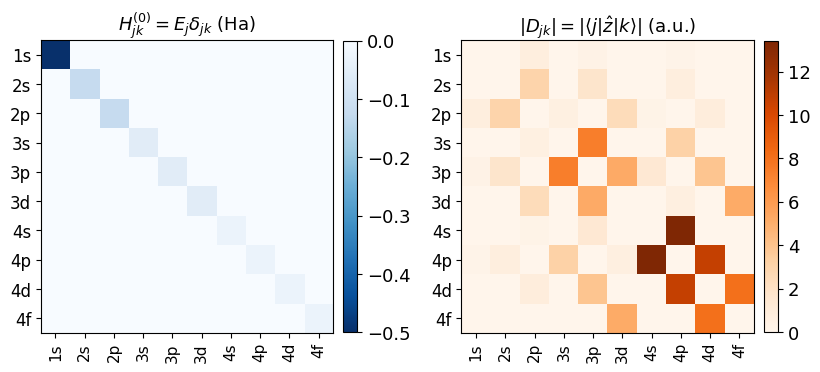

In [4]:
def angular(l1, l2):
    # integral of Y_{l1,0}^* cos(theta) Y_{l2,0}, equation (11)
    if l1 == l2 + 1:
        return l1 / np.sqrt((2 * l1 - 1) * (2 * l1 + 1))
    if l2 == l1 + 1:
        return l2 / np.sqrt((2 * l2 - 1) * (2 * l2 + 1))
    return 0.0

radial_r = (R_all * weights * r_grid**3) @ R_all.T              # radial integrals of r
D = np.array([[radial_r[i, j] * angular(NL[i][1], NL[j][1]) for j in range(DIM)] for i in range(DIM)])

assert np.allclose(D, D.T, atol=1e-12)                                      # real symmetric matrix
assert np.allclose(np.diag(D), 0.0, atol=1e-12)                             # parity, D_nn = 0
for i, (ni, li) in enumerate(NL):
    for j, (nj, lj) in enumerate(NL):
        if abs(li - lj) != 1:
            assert abs(D[i, j]) < 1e-12                                     # selection rule l' = l +- 1
D_eg = D[E_IDX, G_IDX]
assert abs(D_eg - 128 * np.sqrt(2) / 243) < 1e-10                          # equation (12)
print("orbitals coupled to 1s:", [LABELS[j] for j in range(DIM) if abs(D[G_IDX, j]) > 1e-12])
print(f"D(2p,1s) = {D_eg:.6f},  128 sqrt2 / 243 = {128*np.sqrt(2)/243:.6f}")
NUMBERS["DipoleTwopOnes"] = f"{D_eg:.3f}"

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.8))
im0 = axes[0].imshow(H0, cmap="Blues_r")
axes[0].set_title(r"$H^{(0)}_{jk}=E_j\delta_{jk}$ (Ha)")
im1 = axes[1].imshow(np.abs(D), cmap="Oranges")
axes[1].set_title(r"$|D_{jk}|=|\langle j|\hat z|k\rangle|$ (a.u.)")
for ax, im in zip(axes, (im0, im1)):
    ax.set_xticks(range(DIM)); ax.set_xticklabels(LABELS, fontsize=11, rotation=90)
    ax.set_yticks(range(DIM)); ax.set_yticklabels(LABELS, fontsize=12)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.tight_layout(); save(fig, "fig_lab067_orbital_matrices"); plt.show()

The left panel is the Hamiltonian without light, diagonal with the energies of equation (4). The right panel is the dipole matrix. Its nonzero entries form a chessboard pattern, because only orbitals whose $l$ differs by one are coupled, and they grow with $n$, since the outer orbitals are larger. The 1s row couples only to the p orbitals.

The code shows the light term of equation (13) at three moments of one optical period. We choose the field amplitude through the Rabi frequency $\Omega=E_0D_{2p,1s}$ of the future qubit, here $\Omega=0.02$ in atomic units, and tune the laser to the 1s–2p transition.

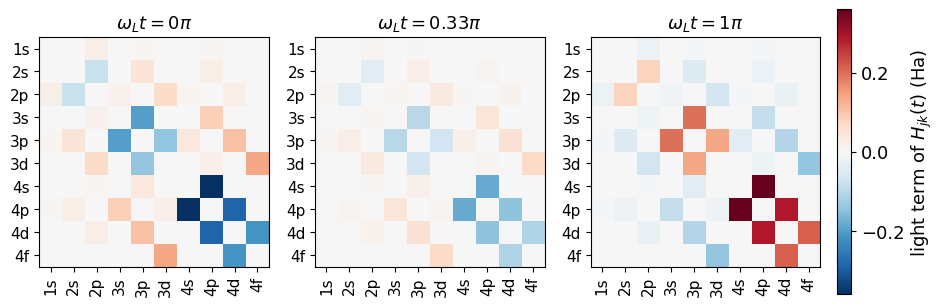

In [5]:
Omega_demo = 0.02
E0_demo = Omega_demo / D_eg
phases = [0.0, np.pi / 3, np.pi]
vmax = E0_demo * np.abs(D).max()
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.7))
for ax, ph in zip(axes, phases):
    light = E0_demo * np.cos(ph) * D                           # off-diagonal part of H(t), equation (13)
    im = ax.imshow(light, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_title(rf"$\omega_Lt={ph/np.pi:.2g}\pi$")
    ax.set_xticks(range(DIM)); ax.set_xticklabels(LABELS, fontsize=11, rotation=90)
    ax.set_yticks(range(DIM)); ax.set_yticklabels(LABELS, fontsize=11)
fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02, label="light term of $H_{jk}(t)$ (Ha)")
save(fig, "fig_lab067_light_snapshots"); plt.show()
H_t = H0 + E0_demo * np.cos(np.pi / 3) * D
assert np.allclose(np.diag(H_t), E_levels) and np.allclose(H_t, H_t.T)

The diagonal of the Hamiltonian matrix stays fixed. Every coupling allowed by the selection rules swings between positive and negative values at the laser frequency and passes through zero a quarter period after its maximum. All allowed entries oscillate together, so at this stage the light seems to couple many orbitals at once.

## 4. The interaction picture and the slow couplings (optional)

*Optional, appendix material. Run the code cells of this section, since later sections use them.*

Without light every amplitude rotates at its own frequency $E_j$. We remove this fast rotation by a change of variables called the interaction picture, writing the state $|\psi(t)\rangle=\sum_jc_j(t)|j\rangle$ with
$$c_j(t)=a_j(t)\,e^{-iE_jt}. \tag{14}$$
Inserting this into the Schrödinger equation $i\dot c_j=\sum_kH_{jk}(t)\,c_k$ cancels the diagonal terms and leaves
$$i\,\dot a_j=\sum_kV_{jk}(t)\,a_k,\qquad V_{jk}(t)=E_0\cos(\omega_Lt-\phi_L)\,D_{jk}\,e^{i\omega_{jk}t},\qquad \omega_{jk}=E_j-E_k. \tag{15}$$
The amplitudes $a_j$ change only through the light, and the coupling matrix $V(t)$ is the light term multiplied by the phases $e^{i\omega_{jk}t}$. For the pair 1s, 2p on resonance, $\omega_L=\omega_{2p,1s}$, the product of the cosine and the phase contains a constant part. For every other pair the frequencies do not match, and the entry oscillates fast. We plot four entries and then average the whole matrix $V(t)$ over two hundred optical periods.

averaged 2p-1s entry: 0.010000   Omega/2 = 0.010000
largest other averaged entry: 4.3e-06


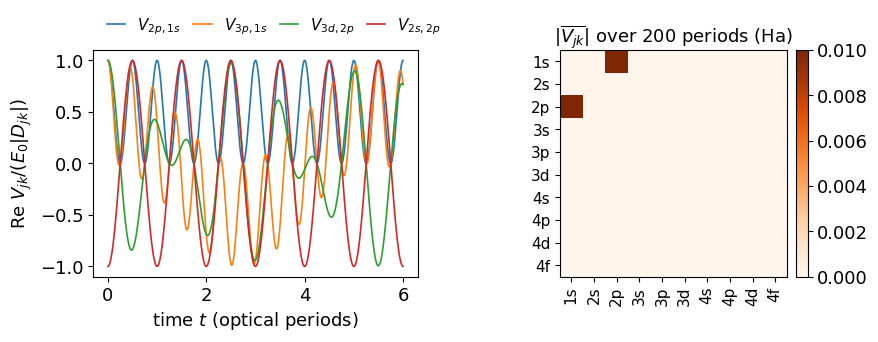

In [6]:
wL = w0                                                        # resonant with 1s-2p
omega_nm = E_levels[:, None] - E_levels[None, :]
def V_matrix(t, E0=E0_demo, wL=wL, phi=0.0):
    return E0 * np.cos(wL * t - phi) * D * np.exp(1j * omega_nm * t)

T_opt = 2 * np.pi / wL
t_trace = np.linspace(0, 6 * T_opt, 1200)
pairs = [("2p", "1s"), ("3p", "1s"), ("3d", "2p"), ("2s", "2p")]
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.6))
for a, b in pairs:
    i, j = LABELS.index(a), LABELS.index(b)
    trace = np.array([V_matrix(t)[i, j].real for t in t_trace]) / (E0_demo * abs(D[i, j]))
    axes[0].plot(t_trace / T_opt, trace, lw=1.2, label=rf"$V_{{{a},{b}}}$")
axes[0].set_xlabel(r"time $t$ (optical periods)"); axes[0].set_ylabel(r"Re $V_{jk}/(E_0|D_{jk}|)$")
axes[0].legend(fontsize=11, ncol=4, loc="lower left", bbox_to_anchor=(0.0, 1.0), frameon=False, handlelength=1.2, columnspacing=0.8)

t_avg = np.linspace(0, 200 * T_opt, 200 * 64, endpoint=False)
V_avg = np.mean([V_matrix(t) for t in t_avg], axis=0)
im = axes[1].imshow(np.abs(V_avg), cmap="Oranges")
axes[1].set_xticks(range(DIM)); axes[1].set_xticklabels(LABELS, fontsize=11, rotation=90)
axes[1].set_yticks(range(DIM)); axes[1].set_yticklabels(LABELS, fontsize=11)
axes[1].set_title(r"$|\overline{V_{jk}}|$ over 200 periods (Ha)")
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.03)
fig.tight_layout(); save(fig, "fig_lab067_interaction_picture"); plt.show()

others = np.abs(V_avg).copy(); others[E_IDX, G_IDX] = others[G_IDX, E_IDX] = 0
print(f"averaged 2p-1s entry: {V_avg[E_IDX, G_IDX].real:.6f}   Omega/2 = {Omega_demo/2:.6f}")
print(f"largest other averaged entry: {others.max():.1e}")
assert abs(V_avg[E_IDX, G_IDX] - Omega_demo / 2) < 1e-6 and others.max() < 1e-3 * Omega_demo

The left panel shows that the 2p–1s entry oscillates around a positive mean, while the entries 3p–1s, 3d–2p and 2s–2p oscillate around zero. The right panel shows the average of the whole matrix. Only the pair 1s, 2p survives, with the value $\Omega/2=E_0D_{2p,1s}/2$, and every other entry averages to less than a thousandth of it. The slow coupling of this one pair is the origin of the two-level system.

## 5. The rotating-wave approximation (optional)

*Optional, appendix material. Run the code cells of this section, since later sections use them.*

We keep only the ground state $|g\rangle=|1s\rangle$ and the excited state $|e\rangle=|2p\rangle$, with the transition frequency $\omega_0=E_e-E_g$ and the detuning $\Delta=\omega_L-\omega_0$ of the laser. Equation (15) for these two amplitudes reads
$$i\,\dot a_g=E_0D_{eg}\cos(\omega_Lt-\phi_L)\,e^{-i\omega_0t}\,a_e,\qquad i\,\dot a_e=E_0D_{eg}\cos(\omega_Lt-\phi_L)\,e^{i\omega_0t}\,a_g. \tag{16}$$
Writing the cosine as $\frac12\big(e^{i(\omega_Lt-\phi_L)}+e^{-i(\omega_Lt-\phi_L)}\big)$ splits the coupling of $a_e$ into two terms,
$$e^{i\omega_0t}\cos(\omega_Lt-\phi_L)=\tfrac12\,e^{i\phi_L}e^{-i\Delta t}+\tfrac12\,e^{-i\phi_L}e^{i(\omega_0+\omega_L)t}. \tag{17}$$
The first term varies slowly, at the detuning $\Delta$. The second oscillates at $\omega_0+\omega_L\approx2\omega_0$. During one Rabi period $2\pi/\Omega$ the slow term turns the amplitudes completely, while the fast term changes them by an amount of order $\Omega/(4\omega_0)$ and then reverses the change. For $\Omega,|\Delta|\ll\omega_0$ we drop the fast term, which is the rotating-wave approximation. With the Rabi frequency $\Omega=E_0D_{eg}$ this leaves
$$i\,\dot a_g=\frac\Omega2\,e^{-i\phi_L}e^{i\Delta t}\,a_e,\qquad i\,\dot a_e=\frac\Omega2\,e^{i\phi_L}e^{-i\Delta t}\,a_g. \tag{18}$$
The remaining time dependence $e^{\pm i\Delta t}$ disappears in the amplitudes $b_g=a_ge^{-i\Delta t/2}$ and $b_e=a_ee^{i\Delta t/2}$. Differentiating and inserting equation (18) gives $i\dot b=\hat{\mathcal H}_{\rm RF}b$ with the constant Hamiltonian
$$\hat{\mathcal H}_{\rm RF}=\begin{pmatrix}\Delta/2&(\Omega/2)\,e^{-i\phi_L}\\(\Omega/2)\,e^{i\phi_L}&-\Delta/2\end{pmatrix}=\frac\Delta2\hat Z+\frac\Omega2\big(\cos\phi_L\,\hat X+\sin\phi_L\,\hat Y\big). \tag{19}$$
The amplitudes $b$ differ from the original $c$ only by phases. With the mean energy $\bar E=(E_g+E_e)/2$ they are
$$\begin{pmatrix}b_g\\b_e\end{pmatrix}=e^{i\bar Et}\,e^{-i\omega_Lt\hat Z/2}\begin{pmatrix}c_g\\c_e\end{pmatrix}, \tag{20}$$
a reference frame that rotates with the laser, and level probabilities are equal in both frames. The same two-level atom without the approximation has the Hamiltonian $-\frac{\omega_0}2\hat Z+\Omega\cos(\omega_Lt-\phi_L)\hat X$, with the zero of energy at $\bar E$.

We compare the two-level evolution with and without the approximation for $\Omega/\omega_0=0.01$, $0.1$ and $0.3$. Before looking at the result, estimate the largest population difference in each case from the ratio $\Omega/(4\omega_0)$.

In [7]:
def evolve(Hfun, T, y0, t_eval=None):
    # integrate i dy/dt = H(t) y with an adaptive Runge-Kutta method of order 8
    f = lambda t, y: -1j * (Hfun(t) @ y)
    return solve_ivp(f, (0.0, T), y0, t_eval=t_eval, rtol=1e-10, atol=1e-12, method="DOP853")

def H_two_level_lab(Omega, wL, phi=0.0):
    return lambda t: -0.5 * w0 * Z + Omega * np.cos(wL * t - phi) * X

g0 = np.array([1, 0], dtype=complex)
rwa_err = {}
curves = {}
for ratio in (0.01, 0.1, 0.3):
    Om = ratio * w0
    T = 2 * np.pi / Om
    t_eval = np.linspace(0, T, 1500)
    sol = evolve(H_two_level_lab(Om, w0), T, g0, t_eval)
    P_full = np.abs(sol.y[1])**2
    P_rwa = np.sin(Om * t_eval / 2)**2                          # resonant solution of equation (19)
    rwa_err[ratio] = np.abs(P_full - P_rwa).max()
    curves[ratio] = (t_eval * Om / (2 * np.pi), P_full, P_rwa)
    print(f"Omega/omega0 = {ratio:4.2f}: largest population difference {rwa_err[ratio]:.4f}")
assert rwa_err[0.01] < 5e-3 and rwa_err[0.01] < rwa_err[0.1] < rwa_err[0.3]
NUMBERS["RwaErrSmall"] = f"{rwa_err[0.01]:.4f}"
NUMBERS["RwaErrMid"] = f"{rwa_err[0.1]:.3f}"
NUMBERS["RwaErrLarge"] = f"{rwa_err[0.3]:.3f}"

Omega/omega0 = 0.01: largest population difference 0.0025
Omega/omega0 = 0.10: largest population difference 0.0258
Omega/omega0 = 0.30: largest population difference 0.0788


The difference grows with the drive strength roughly in proportion to $\Omega/\omega_0$. The fast term of equation (17) also shifts the resonance itself. To measure this shift we use the evolution operator over one optical period $T_L=2\pi/\omega_L$. For a Hamiltonian that repeats with this period, the one-period operator has two eigenvalues with phases. Their difference, divided by $T_L$, is the generalised Rabi frequency $\sqrt{\Omega^2+(\Delta-\delta)^2}$, where $\delta$ is the shift of the resonance. Minimising this frequency over $\omega_L$ locates the resonance. The rotating-wave approximation predicts $\delta=0$, and the dropped term gives the Bloch–Siegert shift
$$\delta_{\rm BS}=\frac{\Omega^2}{4\omega_0}. \tag{21}$$

Omega/omega0 = 0.02: shift 3.749e-05, Omega^2/(4 omega0) = 3.750e-05, ratio 1.000
Omega/omega0 = 0.05: shift 2.341e-04, Omega^2/(4 omega0) = 2.344e-04, ratio 0.999
Omega/omega0 = 0.10: shift 9.334e-04, Omega^2/(4 omega0) = 9.375e-04, ratio 0.996
Omega/omega0 = 0.20: shift 3.685e-03, Omega^2/(4 omega0) = 3.750e-03, ratio 0.983
Omega/omega0 = 0.30: shift 8.115e-03, Omega^2/(4 omega0) = 8.437e-03, ratio 0.962


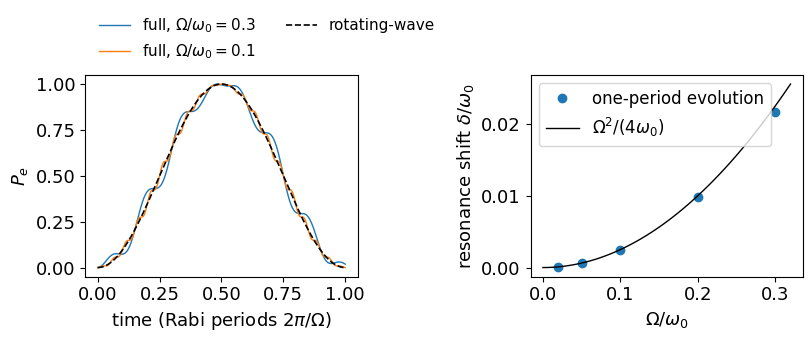

In [8]:
def one_period_operator(Hfun, wL, dim):
    T = 2 * np.pi / wL
    f = lambda t, y: (-1j * Hfun(t) @ y.reshape(dim, dim)).ravel()
    sol = solve_ivp(f, (0.0, T), np.eye(dim, dtype=complex).ravel(), rtol=1e-11, atol=1e-13, method="DOP853")
    return sol.y[:, -1].reshape(dim, dim), T

def rabi_frequency(Hfun_of_wL, wL, dim, qubit_idx):
    # generalised Rabi frequency from the two Floquet phases with most weight on the qubit levels
    U, T = one_period_operator(Hfun_of_wL(wL), wL, dim)
    lam, vec = np.linalg.eig(U)
    weight = (np.abs(vec[qubit_idx, :])**2).sum(axis=0)
    k = np.argsort(weight)[-2:]
    return abs(np.angle(lam[k[0]] / lam[k[1]])) / T

def resonance_shift(Hfun_of_wL, dim, qubit_idx, Om):
    res = minimize_scalar(lambda d: rabi_frequency(Hfun_of_wL, w0 + d, dim, qubit_idx),
                          bounds=(-0.3 * Om, 0.6 * Om), method="bounded", options={"xatol": 1e-9})
    return res.x

bs_ratios = np.array([0.02, 0.05, 0.1, 0.2, 0.3])
bs_shift = np.array([resonance_shift(lambda wl, Om=r*w0: H_two_level_lab(Om, wl), 2, [0, 1], r * w0)
                     for r in bs_ratios])
bs_pred = (bs_ratios * w0)**2 / (4 * w0)
for r, s, p in zip(bs_ratios, bs_shift, bs_pred):
    print(f"Omega/omega0 = {r:4.2f}: shift {s:.3e}, Omega^2/(4 omega0) = {p:.3e}, ratio {s/p:.3f}")
assert abs(bs_shift[0] / bs_pred[0] - 1) < 0.01
NUMBERS["BSRatioSmall"] = f"{bs_shift[0]/bs_pred[0]:.3f}"

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.6))
for ratio, ls in ((0.3, "-"), (0.1, "-")):
    x, Pf, Pr = curves[ratio]
    axes[0].plot(x, Pf, ls, lw=1.0, label=rf"full, $\Omega/\omega_0={ratio}$")
axes[0].plot(curves[0.1][0], curves[0.1][2], "k--", lw=1.2, label="rotating-wave")
axes[0].set_xlabel(r"time (Rabi periods $2\pi/\Omega$)"); axes[0].set_ylabel(r"$P_e$")
axes[0].legend(fontsize=11, ncol=2, loc="lower left", bbox_to_anchor=(0.0, 1.0), frameon=False)
axes[1].plot(bs_ratios, bs_shift / w0, "o", label="one-period evolution")
xs = np.linspace(0, 0.32, 100)
axes[1].plot(xs, xs**2 / 4, "k-", lw=1, label=r"$\Omega^2/(4\omega_0)$")
axes[1].set_xlabel(r"$\Omega/\omega_0$"); axes[1].set_ylabel(r"resonance shift $\delta/\omega_0$")
axes[1].legend(fontsize=12)
fig.tight_layout(); save(fig, "fig_lab067_rwa"); plt.show()

The left panel shows the excited-state population. At $\Omega/\omega_0=0.1$ the full evolution follows the rotating-wave curve with a small ripple at twice the optical frequency, and at $0.3$ the ripple reaches several per cent. The right panel shows that the resonance moves up by $\Omega^2/(4\omega_0)$ for weak drives and less for strong ones, where higher orders matter. The rotating-wave approximation fails for strong drives, $\Omega$ comparable with $\omega_0$, which occur in the ultrastrong coupling of superconducting circuits. Optical transitions of atoms are driven with $\Omega/\omega_0$ far below $10^{-3}$, where the error of the approximation is negligible.

## 6. The two-level system and its Pauli language

The projector on the two levels,
$$\hat P=|g\rangle\langle g|+|e\rangle\langle e|, \tag{22}$$
cuts the atom down to the qubit, and the Hamiltonian of the qubit is the $2\times2$ block $\hat P\hat{\mathcal H}\hat P$. Four operators span all operators on this two-dimensional space, the projectors on the two levels and the two transition operators. With $|g\rangle=|0\rangle=|\uparrow\rangle$ they are
$$|g\rangle\langle g|=\tfrac12(\hat I+\hat Z),\quad |e\rangle\langle e|=\tfrac12(\hat I-\hat Z),\quad |g\rangle\langle e|=\hat S^+=\tfrac12\hat\sigma^+,\quad |e\rangle\langle g|=\hat S^-=\tfrac12\hat\sigma^-, \tag{23}$$
with $\hat\sigma^\pm=\hat X\pm i\hat Y$. Inverting these relations,
$$\hat X=|g\rangle\langle e|+|e\rangle\langle g|,\qquad \hat Y=-i|g\rangle\langle e|+i|e\rangle\langle g|,\qquad \hat Z=|g\rangle\langle g|-|e\rangle\langle e|. \tag{24}$$
In this convention spin up is the ground state, so $\hat\sigma^+$ raises the spin and lowers the energy, and the decay of the excited state is $\hat S^+=|g\rangle\langle e|$.

Atomic-physics texts use a different convention. They write $\hat\sigma_z^{\rm at}=|e\rangle\langle e|-|g\rangle\langle g|=-\hat Z$ and the ladder operators $\hat\sigma^+_{\rm at}=|e\rangle\langle g|$, which excites the atom, and $\hat\sigma^-_{\rm at}=|g\rangle\langle e|$, which lowers it, so $\hat\sigma^\pm_{\rm at}$ correspond to our $\hat S^\mp=\hat\sigma^\mp/2$. In that notation the free atom is $\frac{\omega_0}2\hat\sigma_z^{\rm at}$, and formulas taken from such texts change sign in their $\hat\sigma_z$ terms.

Every Hermitian $2\times2$ matrix has the Pauli expansion
$$\hat{\mathcal H}=c_0\hat I+c_x\hat X+c_y\hat Y+c_z\hat Z,\qquad c_a=\tfrac12\,{\rm Tr}(\hat\sigma_a\hat{\mathcal H}). \tag{25}$$
We build the block of the atom in the rotating frame of equation (20) numerically. The Hamiltonian matrix of equation (13) is projected on the two levels and transformed to the rotating frame. Its average over one optical period gives the coefficients of equation (25). We use a detuning $\Delta=0.3\,\Omega$ and the laser phases $\phi_L=0$ and $\phi_L=\pi/3$.

In [9]:
gg = np.array([[1, 0], [0, 0]], dtype=complex); ee = np.array([[0, 0], [0, 1]], dtype=complex)
ge = np.array([[0, 1], [0, 0]], dtype=complex); eg = ge.T.copy()           # |g><e| and |e><g|
sigma_p, sigma_m = X + 1j * Y, X - 1j * Y
assert np.allclose(gg, (I2 + Z) / 2) and np.allclose(ee, (I2 - Z) / 2)
assert np.allclose(ge, sigma_p / 2) and np.allclose(eg, sigma_m / 2)       # equation (23)
assert np.allclose(X, ge + eg) and np.allclose(Y, -1j * ge + 1j * eg) and np.allclose(Z, gg - ee)

def pauli_coefficients(M):
    return {a: 0.5 * np.trace(s @ M).real for a, s in (("0", I2), ("x", X), ("y", Y), ("z", Z))}

def rotating_frame_block(E0, wL, phi, n_samples=4000):
    # P H(t) P in the rotating frame of equation (20), averaged over one optical period
    idx = [G_IDX, E_IDX]
    Ebar = E_levels[idx].mean()
    ts = np.linspace(0, 2 * np.pi / wL, n_samples, endpoint=False)
    acc = np.zeros((2, 2), dtype=complex)
    for t in ts:
        Hlab = (H0 + E0 * np.cos(wL * t - phi) * D)[np.ix_(idx, idx)] - Ebar * I2
        Rt = np.diag([np.exp(-1j * wL * t / 2), np.exp(1j * wL * t / 2)])   # e^{-i wL t Z/2}
        acc += Rt @ Hlab @ Rt.conj().T + 0.5 * wL * Z                       # R H R^dagger + i (dR/dt) R^dagger
    return acc / n_samples

Delta_demo = 0.3 * Omega_demo
for phi in (0.0, np.pi / 3):
    block = rotating_frame_block(E0_demo, w0 + Delta_demo, phi)
    c = pauli_coefficients(block)
    print(f"phi_L = {phi:.3f}: block =\n{np.round(block, 6)}")
    print("   coefficients:", {k: round(v, 6) for k, v in c.items()})
    assert abs(c["0"]) < 1e-12 and abs(c["z"] - Delta_demo / 2) < 1e-9
    assert abs(c["x"] - Omega_demo / 2 * np.cos(phi)) < 1e-9 and abs(c["y"] - Omega_demo / 2 * np.sin(phi)) < 1e-9

phi_L = 0.000: block =
[[ 0.003-0.j  0.01 -0.j]
 [ 0.01 +0.j -0.003-0.j]]
   coefficients: {'0': np.float64(0.0), 'x': np.float64(0.01), 'y': np.float64(0.0), 'z': np.float64(0.003)}
phi_L = 1.047: block =
[[ 0.003-0.j       0.005-0.00866j]
 [ 0.005+0.00866j -0.003-0.j     ]]
   coefficients: {'0': np.float64(0.0), 'x': np.float64(0.005), 'y': np.float64(0.00866), 'z': np.float64(0.003)}


The averaged block equals equation (19). The coefficient of $\hat Z$ is half the detuning, and the coefficient of $\hat X$ is half the Rabi frequency. The laser phase $\phi_L=\pi/3$ moves part of the weight from $\hat X$ to $\hat Y$ in the ratio $\cos\phi_L:\sin\phi_L$. The coefficient $c_0$ vanishes because we measured energies from the mean level $\bar E$. A nonzero $c_0$ would multiply the state by the global phase $e^{-ic_0t}$, which no measurement detects.

The Pauli expansion translates the physics of the atom into operations on a qubit.

| atom | qubit |
|---|---|
| ground state 1s, excited state 2p | $\lvert 0\rangle$, $\lvert 1\rangle$ |
| detuning $\Delta$, free precession for a time $t$ | rotation $\hat R_z(\Delta t)$ about $z$ |
| resonant pulse of area $\theta=\Omega t$ and phase $\phi_L$ | rotation $\hat R_{\phi_L}(\theta)=e^{-i\theta(\cos\phi_L\hat X+\sin\phi_L\hat Y)/2}$ |
| fluorescence detection of the level | measurement of $\hat Z$ |
| spontaneous decay $e\to g$ | jump operator $\hat S^+=\lvert g\rangle\langle e\rvert$ |

A jump operator describes a sudden transition between two levels, here the emission of a photon that takes the atom from $e$ to $g$.

## 7. The full driven atom (optional)

*Optional, appendix material. Run the code cells of this section, since later sections use them.*

We test these approximations on the full atom by integrating the Schrödinger equation with the Hamiltonian matrix of equation (13) for all ten orbitals, without any approximation in time. The atom starts in 1s, and the resonant laser has the Rabi frequency $\Omega=0.005$. One Rabi period then lasts about 75 optical periods. The corresponding field, $E_0\approx3.5\times10^9$ V/m, is much stronger than in a laboratory, where Rabi periods span millions of optical periods. The ratio $\Omega/\omega_0\approx0.013$ keeps the physics of a weak drive while the simulation stays short. The two-level prediction on resonance is $P_{2p}(t)=\sin^2(\Omega t/2)$, and for a detuning $\Delta$ the largest population reached is
$$P_{2p}^{\max}=\frac{\Omega^2}{\Omega^2+\Delta^2},\qquad\text{at the time }t=\frac\pi{\sqrt{\Omega^2+\Delta^2}}. \tag{26}$$

field E0 = 0.0067 a.u. = 3.45e+09 V/m, optical periods per Rabi period: 75
largest deviation from sin^2(Omega t/2): 0.0066, largest population outside 1s, 2p: 0.0050
largest deviation from equation (26): 0.0187


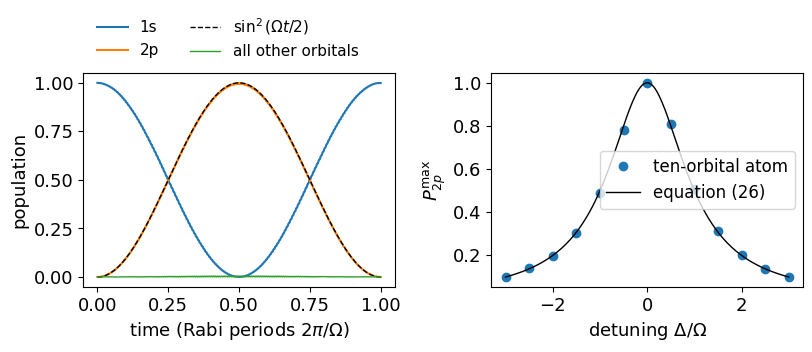

In [10]:
def H_atom(E0, wL, phi=0.0):
    return lambda t: H0 + E0 * np.cos(wL * t - phi) * D

def ground_state():
    y = np.zeros(DIM, dtype=complex); y[G_IDX] = 1.0
    return y

Omega_w = 0.005
E0_w = Omega_w / D_eg
T_rabi = 2 * np.pi / Omega_w
t_eval = np.linspace(0, T_rabi, 600)
sol = evolve(H_atom(E0_w, w0), T_rabi, ground_state(), t_eval)
P = np.abs(sol.y)**2
P_rabi = np.sin(Omega_w * t_eval / 2)**2
rabi_err = np.abs(P[E_IDX] - P_rabi).max()
other_max = (1 - P[G_IDX] - P[E_IDX]).max()
print(f"field E0 = {E0_w:.4f} a.u. = {E0_w * F_AU:.2e} V/m, optical periods per Rabi period: {T_rabi / (2*np.pi/w0):.0f}")
print(f"largest deviation from sin^2(Omega t/2): {rabi_err:.4f}, largest population outside 1s, 2p: {other_max:.4f}")
assert rabi_err < 1e-2 and other_max < 1e-2
NUMBERS["FieldVm"] = f"{E0_w * F_AU / 1e9:.1f}"
NUMBERS["RabiErr"] = f"{rabi_err:.4f}"
NUMBERS["OtherMax"] = f"{other_max:.4f}"

detunings = np.linspace(-3, 3, 13) * Omega_w
Pmax_sim, Pmax_th = [], []
for Dl in detunings:
    Oeff = np.hypot(Omega_w, Dl); Tp = np.pi / Oeff
    s = evolve(H_atom(E0_w, w0 + Dl), Tp, ground_state(), [Tp])
    Pmax_sim.append(abs(s.y[E_IDX, -1])**2); Pmax_th.append(Omega_w**2 / Oeff**2)
Pmax_sim, Pmax_th = np.array(Pmax_sim), np.array(Pmax_th)
detune_err = np.abs(Pmax_sim - Pmax_th).max()
print(f"largest deviation from equation (26): {detune_err:.4f}")
assert detune_err < 2e-2
NUMBERS["DetuneErr"] = f"{detune_err:.3f}"

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.7))
x = t_eval / T_rabi
axes[0].plot(x, P[G_IDX], lw=1.5, label="1s")
axes[0].plot(x, P[E_IDX], lw=1.5, label="2p")
axes[0].plot(x, P_rabi, "k--", lw=1, label=r"$\sin^2(\Omega t/2)$")
axes[0].plot(x, 1 - P[G_IDX] - P[E_IDX], lw=1, label="all other orbitals")
axes[0].set_xlabel(r"time (Rabi periods $2\pi/\Omega$)"); axes[0].set_ylabel("population")
axes[0].legend(fontsize=11, ncol=2, loc="lower left", bbox_to_anchor=(0.0, 1.0), frameon=False)
axes[1].plot(detunings / Omega_w, Pmax_sim, "o", label="ten-orbital atom")
dd = np.linspace(-3, 3, 200)
axes[1].plot(dd, 1 / (1 + dd**2), "k-", lw=1, label="equation (26)")
axes[1].set_xlabel(r"detuning $\Delta/\Omega$"); axes[1].set_ylabel(r"$P_{2p}^{\max}$")
axes[1].legend(fontsize=12)
fig.tight_layout(); save(fig, "fig_lab067_rabi"); plt.show()

The populations of 1s and 2p exchange with the Rabi period and follow the two-level curve to better than one per cent. All other orbitals together never hold more than about half a per cent. The detuning scan follows the Lorentzian of equation (26). The atom with ten orbitals behaves as a two-level system with the Rabi frequency computed from the single matrix element of equation (12).

## 8. Limits of the two-level description (optional)

*Optional, appendix material. Run the code cells of this section, since later sections use them.*

The other orbitals are nearly empty, and they still shift the qubit levels. A level $r$ coupled to a level $n$ with the Rabi frequency $\Omega_{nr}=E_0D_{nr}$ shifts its energy, to second order in the field, by
$$\delta E_n=\sum_{r}\frac{\Omega_{nr}^2}{4}\left(\frac1{\omega_{nr}-\omega_L}+\frac1{\omega_{nr}+\omega_L}\right), \tag{27}$$
where the resonant term of the qubit pair itself is left out because the rotating-wave approximation keeps it in full. The counter-rotating term of the pair is kept, and it reproduces the Bloch–Siegert shift of equation (21). The shift of the qubit resonance is $\delta=\delta E_e-\delta E_g$, the light shift. It grows with the square of the field, and so does the population that leaks into the other orbitals during a pulse.

Before looking at the result, decide how the leakage changes when the Rabi frequency doubles.

Omega = 0.01: resonance shift 4.857e-04, equation (27) 4.894e-04, ratio 0.993
Omega = 0.02: resonance shift 1.902e-03, equation (27) 1.957e-03, ratio 0.972
Omega = 0.04: resonance shift 7.066e-03, equation (27) 7.830e-03, ratio 0.902
largest leakage during a pi pulse: {np.float64(0.005): np.float64(0.0057), np.float64(0.01): np.float64(0.02237), np.float64(0.02): np.float64(0.08845), np.float64(0.04): np.float64(0.30507), np.float64(0.08): np.float64(0.6138)}  log-log slope 1.98


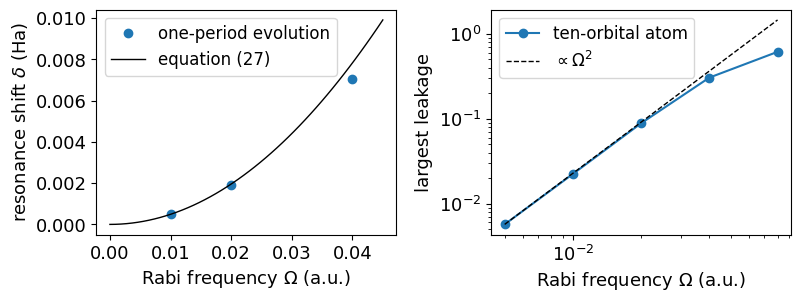

In [11]:
def predicted_shift(E0, wL):
    dE = np.zeros(DIM)
    for n in range(DIM):
        for m in range(DIM):
            if n == m or abs(D[n, m]) < 1e-12:
                continue
            Om_nm = E0 * D[n, m]
            for sign in (+1, -1):
                den = omega_nm[n, m] + sign * wL
                if {n, m} == {G_IDX, E_IDX} and abs(den) < 0.5 * wL:
                    continue                                    # resonant term of the qubit pair
                if abs(den) > 1e-12:
                    dE[n] += Om_nm**2 / 4 / den
    return dE[E_IDX] - dE[G_IDX]

shift_Omegas = np.array([0.01, 0.02, 0.04])
shift_num = np.array([resonance_shift(lambda wl, E0=Om/D_eg: H_atom(E0, wl), DIM, [G_IDX, E_IDX], Om)
                      for Om in shift_Omegas])
shift_pred = np.array([predicted_shift(Om / D_eg, w0) for Om in shift_Omegas])
for Om, s, p in zip(shift_Omegas, shift_num, shift_pred):
    print(f"Omega = {Om:.2f}: resonance shift {s:.3e}, equation (27) {p:.3e}, ratio {s/p:.3f}")
assert abs(shift_num[0] / shift_pred[0] - 1) < 0.02
NUMBERS["ShiftNum"] = f"{shift_num[1]:.2e}"
NUMBERS["ShiftPred"] = f"{shift_pred[1]:.2e}"

leak_Omegas = np.array([0.005, 0.01, 0.02, 0.04, 0.08])
leakage = []
for Om in leak_Omegas:
    Tp = np.pi / Om
    s = evolve(H_atom(Om / D_eg, w0), Tp, ground_state(), np.linspace(0, Tp, 400))
    Pq = np.abs(s.y[G_IDX])**2 + np.abs(s.y[E_IDX])**2
    leakage.append((1 - Pq).max())
leakage = np.array(leakage)
slope = np.polyfit(np.log(leak_Omegas[:3]), np.log(leakage[:3]), 1)[0]          # weak-field slope
print("largest leakage during a pi pulse:", dict(zip(leak_Omegas, np.round(leakage, 5))), f" log-log slope {slope:.2f}")
assert 1.6 < slope < 2.4
NUMBERS["LeakSlope"] = f"{slope:.1f}"
NUMBERS["LeakStrong"] = f"{leakage[-1]:.3f}"

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.2))
axes[0].plot(shift_Omegas, shift_num, "o", label="one-period evolution")
oo = np.linspace(0, 0.045, 50)
axes[0].plot(oo, [predicted_shift(o / D_eg, w0) for o in oo], "k-", lw=1, label="equation (27)")
axes[0].set_xlabel(r"Rabi frequency $\Omega$ (a.u.)"); axes[0].set_ylabel(r"resonance shift $\delta$ (Ha)")
axes[0].legend(fontsize=12)
axes[1].loglog(leak_Omegas, leakage, "o-", label="ten-orbital atom")
axes[1].loglog(leak_Omegas, leakage[0] * (leak_Omegas / leak_Omegas[0])**2, "k--", lw=1, label=r"$\propto\Omega^2$")
axes[1].set_xlabel(r"Rabi frequency $\Omega$ (a.u.)"); axes[1].set_ylabel("largest leakage")
axes[1].legend(fontsize=12)
fig.tight_layout(); save(fig, "fig_lab067_limits"); plt.show()

The left panel shows that the resonance of the ten-orbital atom moves with the square of the field, as equation (27) predicts. The prediction agrees within one per cent at the weakest field. The light shift is several times larger than the Bloch–Siegert shift of the isolated pair, because the 2p level couples strongly to 3d and 3s. The right panel shows that the leakage out of the qubit grows as $\Omega^2$ at weak fields, so doubling the Rabi frequency quadruples it. The leakage reaches tens of per cent when $\Omega/\omega_0$ approaches 0.1. A laser tuned to the bare transition frequency is therefore slightly detuned from the shifted resonance, and a fast gate leaks more. Both effects set a speed limit for gates on a given atom. The basis of ten orbitals omits the higher bound states and the continuum, which add further small shifts of the same kind.

## 9. Spontaneous emission (optional)

*Optional, appendix material. Run the code cells of this section, since later sections use them.*

The excited level also decays by emitting a photon, an effect of the quantised light field that the classical description used here does not contain. Its rate is
$$\Gamma=\frac{\omega_0^3\,|d_{eg}|^2}{3\pi\varepsilon_0\hbar c^3}, \tag{28}$$
with the dipole matrix element $d_{eg}=-e_0a_0D_{2p,1s}$ and the speed of light $c$. We evaluate it in SI units.

In [12]:
w0_SI = w0 / T_AU                                              # rad/s
d_SI = const.e * A0_M * D_eg                                   # C m
Gamma = w0_SI**3 * d_SI**2 / (3 * np.pi * const.epsilon_0 * const.hbar * const.c**3)
lifetime_ns = 1e9 / Gamma
cycles = w0_SI / (2 * np.pi) / Gamma
print(f"Gamma = {Gamma:.3e} 1/s, lifetime 1/Gamma = {lifetime_ns:.3f} ns, optical cycles per lifetime {cycles:.2e}")
assert 1.5 < lifetime_ns < 1.7
NUMBERS["LifetimeNs"] = f"{lifetime_ns:.2f}"
NUMBERS["CyclesPerLifetime"] = f"{cycles/1e6:.1f}"

Gamma = 6.268e+08 1/s, lifetime 1/Gamma = 1.595 ns, optical cycles per lifetime 3.94e+06


The 2p level of hydrogen lives about 1.6 ns, roughly four million optical cycles. Over the short pulses simulated here the decay is negligible, so the closed two-level description holds. For computation, which needs many gates in sequence, a nanosecond is far too short. Atomic and ionic qubits therefore use pairs of long-lived levels, such as two hyperfine levels of the ground state or a metastable excited state. They are driven with microwaves, with pairs of laser beams or on narrow optical transitions. For each such pair the matrix element of the drive between the two levels takes the place of the dipole matrix element $d_{eg}$, and the rotating-wave approximation gives the Hamiltonian of equation (19) with the Rabi frequency set by that matrix element. The decay that remains appears in the qubit language as the jump $\hat S^+=|g\rangle\langle e|$ with the relaxation time $T_1=1/\Gamma$.

## 10. Laser pulses as quantum gates

A resonant pulse of duration $t$ rotates the qubit by the angle $\theta=\Omega t$ about the axis $(\cos\phi_L,\sin\phi_L,0)$ of the Bloch sphere, by equation (19). A $\pi/2$ pulse takes the ground state to the equator, and a $\pi$ pulse exchanges the two levels. We apply such pulses to the ten-orbital atom and transform the 1s and 2p amplitudes to the rotating frame with equation (20). Their Bloch vector is
$$\mathbf r=\big(\langle\hat X\rangle,\langle\hat Y\rangle,\langle\hat Z\rangle\big)=\big(2\,{\rm Re}(b_g^*b_e),\;2\,{\rm Im}(b_g^*b_e),\;|b_g|^2-|b_e|^2\big). \tag{29}$$
For the ideal rotation $\hat R_{\phi_L}(\theta)$ the Bloch vector starting at the north pole moves to $(\sin\theta\sin\phi_L,\,-\sin\theta\cos\phi_L,\,\cos\theta)$. To compare a pulse on the full atom with the ideal gate we use the average gate fidelity of the $2\times2$ block $U$ of the evolution, $F=\big(|{\rm Tr}(U_{\rm ideal}^\dagger U)|^2+{\rm Tr}(U^\dagger U)\big)/6$. It equals one only for the ideal gate and drops when population leaks out of the qubit.

pi/2 pulse, phi_L = 0.000: final Bloch vector [-0.018 -0.996  0.002], ideal [ 0. -1.  0.]
pi/2 pulse, phi_L = 1.571: final Bloch vector [ 0.999 -0.031 -0.   ], ideal [ 1. -0.  0.]
pi pulse with Omega = 0.005: gate error 1 - F = 6.03e-04
pi pulse with Omega = 0.040: gate error 1 - F = 1.74e-01


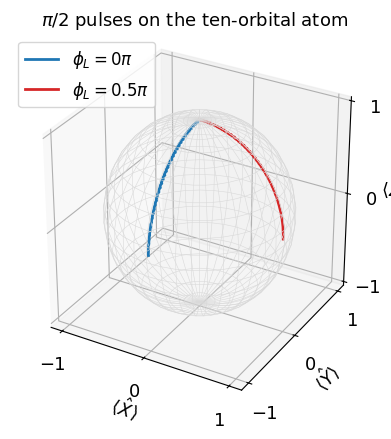

In [13]:
def rotating_amplitudes(c_full, t, wL):
    idx = [G_IDX, E_IDX]
    Ebar = E_levels[idx].mean()
    phase = np.exp(1j * Ebar * t) * np.array([np.exp(-1j * wL * t / 2), np.exp(1j * wL * t / 2)])
    return phase * c_full[idx]

def bloch(b):
    rho01 = np.conj(b[0]) * b[1]
    return np.array([2 * rho01.real, 2 * rho01.imag, np.abs(b[0])**2 - np.abs(b[1])**2])

trajectories = {}
for phi in (0.0, np.pi / 2):
    Tp = (np.pi / 2) / Omega_w
    ts = np.linspace(0, Tp, 200)
    s = evolve(H_atom(E0_w, w0, phi), Tp, ground_state(), ts)
    b = rotating_amplitudes(s.y, ts, w0)
    r = bloch(b)
    ideal_end = np.array([np.sin(np.pi / 2) * np.sin(phi), -np.sin(np.pi / 2) * np.cos(phi), np.cos(np.pi / 2)])
    print(f"pi/2 pulse, phi_L = {phi:.3f}: final Bloch vector {np.round(r[:, -1], 3)}, ideal {np.round(ideal_end, 3)}")
    assert np.linalg.norm(r[:, -1] - ideal_end) < 5e-2
    trajectories[phi] = r

def pulse_block(Om, theta, phi):
    # 2x2 block of the evolution of the ten-orbital atom in the rotating frame
    Tp = theta / Om
    cols = []
    for start in (G_IDX, E_IDX):
        y0 = np.zeros(DIM, dtype=complex); y0[start] = 1.0
        s = evolve(H_atom(Om / D_eg, w0, phi), Tp, y0, [Tp])
        cols.append(rotating_amplitudes(s.y, np.array([Tp]), w0)[:, 0])
    return np.array(cols).T

def gate_fidelity(U, theta, phi):
    U_ideal = expm(-1j * theta / 2 * (np.cos(phi) * X + np.sin(phi) * Y))
    return (abs(np.trace(U_ideal.conj().T @ U))**2 + np.trace(U.conj().T @ U).real) / 6

infid = {}
for Om in (Omega_w, 0.04):
    U = pulse_block(Om, np.pi, 0.0)
    infid[Om] = 1 - gate_fidelity(U, np.pi, 0.0)
    print(f"pi pulse with Omega = {Om:.3f}: gate error 1 - F = {infid[Om]:.2e}")
assert infid[Omega_w] < infid[0.04] and infid[Omega_w] < 1e-2
NUMBERS["GateErrWeak"] = f"{infid[Omega_w]:.1e}"
NUMBERS["GateErrStrong"] = f"{infid[0.04]:.1e}"

fig = plt.figure(figsize=(5.4, 4.8))
ax = fig.add_subplot(projection="3d")
u, v = np.mgrid[0:2*np.pi:40j, 0:np.pi:20j]
ax.plot_wireframe(np.cos(u)*np.sin(v), np.sin(u)*np.sin(v), np.cos(v), color="0.85", lw=0.4)
for phi, col in ((0.0, "C0"), (np.pi / 2, "C3")):
    r = trajectories[phi]
    ax.plot(r[0], r[1], r[2], color=col, lw=2, label=rf"$\phi_L={phi/np.pi:.1g}\pi$")
ax.zaxis.set_rotate_label(False)
ax.set_xlabel(r"$\langle\hat X\rangle$", labelpad=2); ax.set_ylabel(r"$\langle\hat Y\rangle$", labelpad=2)
ax.set_zlabel(r"$\langle\hat Z\rangle$", rotation=0, labelpad=2)
ax.set_xticks([-1, 0, 1]); ax.set_yticks([-1, 0, 1]); ax.set_zticks([-1, 0, 1])
ax.set_box_aspect((1, 1, 1)); ax.legend(fontsize=12, loc="upper left")
ax.set_title(r"$\pi/2$ pulses on the ten-orbital atom")
save(fig, "fig_lab067_pulses"); plt.show()

Both $\pi/2$ pulses start at the north pole, the ground state, and end on the equator. The laser phase turns the axis of rotation, so the pulse with $\phi_L=0$ ends at $-y$ and the pulse with $\phi_L=\pi/2$ ends at $+x$. The ten-orbital atom therefore performs the rotations $\hat R_{\phi_L}(\theta)$ of the qubit. At the weak field the $\pi$ pulse has a gate error below one per cent. At the eight-fold stronger field the error grows, because the light shift detunes the laser from the shifted resonance and population leaks out of the qubit. On the same atom a faster gate is therefore less accurate unless the laser frequency is corrected for the light shift.

### Rotation angles set by pulse area

On resonance the qubit Hamiltonian in the rotating frame is $\frac{\Omega(t)}2(\cos\phi_L\hat X+\sin\phi_L\hat Y)$, where the Rabi frequency $\Omega(t)$ follows the envelope of the laser field. At different times this Hamiltonian differs only by the number $\Omega(t)$, so it commutes with itself, and the product of many short steps collapses to one exponential,
$$\hat U=\hat R_{\phi_L}(\theta)=e^{-i\theta(\cos\phi_L\hat X+\sin\phi_L\hat Y)/2},\qquad \theta=\int_0^T\Omega(t')\,dt' . \tag{30}$$
The rotation angle is the pulse area. A rectangular pulse gives $\theta=\Omega T$, so the angle grows linearly with the duration, and a smooth envelope of the same area gives the same gate. The laser phase only turns the axis. A rotation about $z$ turns $\hat X$ into $\hat R_z(\phi)\hat X\hat R_z(-\phi)=\cos\phi\,\hat X+\sin\phi\,\hat Y$, which gives
$$\hat R_{\phi}(\theta)=\hat R_z(\phi)\,\hat R_x(\theta)\,\hat R_z(-\phi),\qquad \hat R_{\phi}(\theta)\,\hat R_z(\beta)=\hat R_z(\beta)\,\hat R_{\phi-\beta}(\theta). \tag{31}$$
A rotation by $\beta$ about $z$ before a sequence of pulses therefore equals the same pulses with all phases shifted by $-\beta$, followed by a final rotation about $z$. That final rotation leaves the probabilities of a readout in the computational basis unchanged. A laboratory applies such rotations by shifting the phases of later pulses, without any pulse at all.

Predict the rotation angle of a $\sin^2$ pulse of peak Rabi frequency $\Omega_0$ and duration $T$ before running the code. The code integrates the two-level Hamiltonian for rectangular pulses of increasing duration and for a $\sin^2$ envelope, and it compares the result with equations (30) and (31).

In [14]:
def time_ordered(H_of_t, T, n=2000):
    # product of short exponentials, latest step leftmost (midpoint rule)
    dt = T / n
    U = np.eye(2, dtype=complex)
    for k in range(n):
        U = expm(-1j * dt * H_of_t((k + 0.5) * dt)) @ U
    return U

def R_phi(theta, phi):
    return expm(-1j * theta / 2 * (np.cos(phi) * X + np.sin(phi) * Y))

Om_c, phi_c = 1.0, 0.4
durations = np.linspace(0.0, 2 * np.pi, 9)
angles = []
for T in durations:
    U = expm(-1j * T * (Om_c / 2) * (np.cos(phi_c) * X + np.sin(phi_c) * Y))
    # angle from the trace, Tr U = 2 cos(theta/2)
    angles.append(2 * np.arccos(np.clip(np.trace(U).real / 2, -1, 1)))
angles = np.array(angles)
assert np.allclose(angles, Om_c * durations, atol=1e-9)          # theta = Omega T, linear in T

T_s, Om0 = 3.0, 1.7
envelope = lambda t: Om0 * np.sin(np.pi * t / T_s) ** 2
area = Om0 * T_s / 2
U_shaped = time_ordered(lambda t: 0.5 * envelope(t) * (np.cos(phi_c) * X + np.sin(phi_c) * Y), T_s)
err_shaped = np.max(np.abs(U_shaped - R_phi(area, phi_c)))
assert err_shaped < 1e-5                                           # equation (30)

Rz_ = lambda a: expm(-1j * a * Z / 2)
alpha = 0.9
assert np.allclose(R_phi(1.3, phi_c), Rz_(phi_c) @ R_phi(1.3, 0.0) @ Rz_(-phi_c))      # equation (31), left
assert np.allclose(R_phi(1.3, phi_c) @ Rz_(alpha), Rz_(alpha) @ R_phi(1.3, phi_c - alpha))  # equation (31), right
psi = R_phi(0.7, 0.0) @ np.array([1, 0], dtype=complex)
with_z = R_phi(0.8, 1.1) @ R_phi(1.9, 0.3) @ Rz_(alpha) @ psi
shifted = R_phi(0.8, 1.1 - alpha) @ R_phi(1.9, 0.3 - alpha) @ psi
assert np.allclose(np.abs(with_z) ** 2, np.abs(shifted) ** 2)
print(f"angle = Omega T on {len(durations)} durations; sin^2 pulse of area {area:.3f} reproduces R_phi(area) to {err_shaped:.1e}")
print("a z rotation equals a phase shift of the later pulses for a computational-basis readout")


angle = Omega T on 9 durations; sin^2 pulse of area 2.550 reproduces R_phi(area) to 1.3e-15
a z rotation equals a phase shift of the later pulses for a computational-basis readout


### Single-qubit gates as pulses

Every single-qubit gate is a short sequence of resonant pulses and rotations about $z$. A pulse of area $\theta$ and phase $\phi_L$ applies $\hat R_{\phi_L}(\theta)$ of equation (30), so $\phi_L=0$ gives $\hat R_x(\theta)$ and $\phi_L=\pi/2$ gives $\hat R_y(\theta)$. A pulse of area $\pi$ is $\hat X$ up to the global phase $-i$, and a pulse of area $\pi/2$ takes $|0\rangle$ to $(|0\rangle-i|1\rangle)/\sqrt2$. With the laser off, $\Omega=0$, only the detuning acts, and a waiting time $t$ gives the precession $\hat R_z(\Delta t)$. By equation (31) a rotation about $z$ can also be applied by shifting the phases of all later pulses, which takes no time and is called a *virtual* $\hat Z$ gate.

| gate | implementation |
|---|---|
| $\hat X$ | pulse of area $\pi$, $\phi_L=0$ |
| $\hat Y$ | pulse of area $\pi$, $\phi_L=\pi/2$ |
| $\hat Z$, $\hat S$, $\hat T$ | virtual $\hat Z$ gate by $\pi$, $\pi/2$, $\pi/4$, or detuning for $\Delta t=\pi,\pi/2,\pi/4$ |
| $\hat H=\hat R_y(\pi/2)\hat Z$ | virtual $\hat Z$ gate by $\pi$, then a pulse of area $\pi/2$ with $\phi_L=\pi/2$ |
| $\hat R_x(\theta)$, $\hat R_y(\theta)$ | pulse of area $\theta$ with $\phi_L=0$ or $\pi/2$ |
| $\hat R_z(\theta)$ | virtual $\hat Z$ gate by $\theta$, or detuning with $\Delta t=\theta$ |

The code checks every row up to a global phase.

In [15]:
# every single-qubit gate as a pulse sequence, equal up to a global phase
pulse = lambda theta, phi: R_phi(theta, phi)                        # resonant pulse of area theta and phase phi
def equal_up_to_phase(A, B):
    k = np.argmax(np.abs(B)); ph = A.flat[k] / B.flat[k]
    return abs(abs(ph) - 1) < 1e-12 and np.allclose(A, ph * B)
Hd = (X + Z) / np.sqrt(2); S_g = np.diag([1, 1j]); T_g = np.diag([1, np.exp(1j * np.pi / 4)])
Rz_free = lambda a: expm(-1j * a * Z / 2)                            # detuning Delta for a time a/Delta
checks = {"X": (X, pulse(np.pi, 0)), "Y": (Y, pulse(np.pi, np.pi / 2)), "Z": (Z, Rz_free(np.pi)),
          "S": (S_g, Rz_free(np.pi / 2)), "T": (T_g, Rz_free(np.pi / 4)),
          "H": (Hd, pulse(np.pi / 2, np.pi / 2) @ Rz_free(np.pi)),
          "R_x": (expm(-0.7j * X / 2), pulse(0.7, 0)), "R_y": (expm(-0.7j * Y / 2), pulse(0.7, np.pi / 2))}
for name, (G, P) in checks.items():
    assert equal_up_to_phase(G, P), name
assert np.allclose(pulse(np.pi, 0), -1j * X)                                                    # pi pulse = -i X
assert np.allclose(pulse(np.pi / 2, 0) @ np.array([1, 0]), np.array([1, -1j]) / np.sqrt(2))     # pi/2 pulse
print("X, Y, Z, S, T, H, R_x and R_y equal their pulse sequences up to a global phase")

X, Y, Z, S, T, H, R_x and R_y equal their pulse sequences up to a global phase


## 11. A superconducting circuit as a qubit

An atom provides a qubit because its levels are unequally spaced, so that a laser tuned to one transition leaves all other transitions far from resonance. An electrical circuit made of superconducting metal and cooled close to absolute zero behaves as a quantum system with discrete levels, whose spacing is engineered. An inductance $L$ connected to a capacitance $C$ forms an LC oscillator. The charge $\hat Q$ on the capacitor and the magnetic flux $\hat\Phi$ through the inductor are conjugate operators, $[\hat\Phi,\hat Q]=i$ with $\hbar=1$, and the energy of the circuit is
$$\hat{\mathcal H}_{LC}=\frac{\hat Q^2}{2C}+\frac{\hat\Phi^2}{2L} . \tag{32}$$
Equation (32) describes a harmonic oscillator with the position $\hat\Phi$, the momentum $\hat Q$, the mass $C$ and the angular frequency $\omega_r=1/\sqrt{LC}$. Its levels $E_k=\omega_r(k+\tfrac12)$, $k=0,1,2,\dots$, are equally spaced. A microwave drive tuned to the transition $0\to1$ is then resonant with $1\to2$, $2\to3$ and every higher transition, and it pushes the circuit up the whole ladder. A harmonic oscillator therefore cannot serve as a qubit.

In the transmon the inductor is replaced by a Josephson junction, two superconductors separated by an insulating barrier about a nanometre thick. Cooper pairs, the bound electron pairs that carry the current in a superconductor, tunnel through the barrier. The energy of the junction depends on the difference $\phi_J$ of the quantum phases of the two superconductors as $-E_J\cos\phi_J$, with the Josephson energy $E_J$ (B. D. Josephson, Phys. Lett. **1**, 251 (1962), https://doi.org/10.1016/0031-9163(62)91369-0). We write the junction phase with the subscript $J$ to keep it apart from the azimuth $\varphi$ of the Bloch sphere and from the laser phase $\phi_L$. With $\hbar=1$ the phase is related to the flux by $\hat\phi_J=2e_0\hat\Phi$, and the number of Cooper pairs that have passed through the junction is $\hat n=\hat Q/2e_0$, so that $[\hat\phi_J,\hat n]=[\hat\Phi,\hat Q]=i$. The capacitive energy becomes $\hat Q^2/2C=4E_C\hat n^2$ with the charging energy $E_C=e_0^2/2C$ of one electron on the total capacitance $C$. A junction in parallel with a large capacitor forms the transmon (J. Koch et al., Phys. Rev. A **76**, 042319 (2007), https://doi.org/10.1103/PhysRevA.76.042319), whose Hamiltonian is
$$\hat{\mathcal H}_{\rm tr}=4E_C(\hat n-n_g)^2-E_J\cos\hat\phi_J,\qquad [\hat\phi_J,\hat n]=i . \tag{33}$$
The offset charge $n_g$, in units of $2e_0$, is set by the electrostatic environment. The junction energy depends on $\hat\phi_J$ only through $\cos\hat\phi_J$, so the phase is an angle defined modulo $2\pi$, and $\hat n$ has integer eigenvalues. We use its eigenstates $|n\rangle$, with $n=0,\pm1,\pm2,\dots$, as a basis. The commutator gives $[\hat n,e^{i\hat\phi_J}]=e^{i\hat\phi_J}$, so $e^{i\hat\phi_J}$ raises the eigenvalue of $\hat n$ by one, $e^{i\hat\phi_J}|n\rangle=|n+1\rangle$, and transfers one Cooper pair. Hence
$$\cos\hat\phi_J=\tfrac12\sum_n\big(|n+1\rangle\langle n|+|n\rangle\langle n+1|\big) . \tag{34}$$
In this charge basis the Hamiltonian (33) is a tridiagonal matrix, with $4E_C(n-n_g)^2$ on the diagonal and $-E_J/2$ next to it, which we truncate at $|n|\le20$ and diagonalise.

A transmon has $E_J/E_C$ of about 50 or more, and its levels then depend on $n_g$ only weakly. For $E_J\gg E_C$ the phase stays near the bottom of the cosine well and never reaches $\pm\pi$, so it behaves as an ordinary coordinate on a line. The factor $e^{in_g\hat\phi_J}$ then shifts $\hat n$ by $n_g$ and removes the offset charge from the Hamiltonian. We expand $-E_J\cos\hat\phi_J\approx-E_J+\frac{E_J}2\hat\phi_J^2-\frac{E_J}{24}\hat\phi_J^4$. The quadratic part together with $4E_C\hat n^2$ is a harmonic oscillator of mass $1/8E_C$ and angular frequency $\omega_p=\sqrt{8E_JE_C}$. With its lowering operator $\hat b$ the phase is $\hat\phi_J=\phi_0(\hat b+\hat b^\dagger)$ with $\phi_0^2=1/(2m\omega_p)=\sqrt{2E_C/E_J}$. In first-order perturbation theory the quartic term lowers the level $k$ by $\frac{E_J}{24}\langle k|\hat\phi_J^4|k\rangle=\frac{E_J}{24}\phi_0^4(6k^2+6k+3)=\frac{E_C}{12}(6k^2+6k+3)$, so
$$\omega_{01}=E_1-E_0\approx\sqrt{8E_JE_C}-E_C,\qquad \alpha=\omega_{12}-\omega_{01}\approx-E_C . \tag{35}$$
The anharmonicity $\alpha$ is the difference between the frequencies of the second and the first transition. Although $\alpha$ is small compared with $\omega_{01}$, a drive at $\omega_{01}$ that is weak and slow compared with $|\alpha|$ excites only the transition $0\to1$. We measure energies as frequencies $E/h$ in gigahertz, so an angular frequency $\omega$ corresponds to $\omega/2\pi=E/h$. We choose $E_C/h=0.25$ GHz and $E_J=50\,E_C$, values within the range of present devices (P. Krantz et al., Appl. Phys. Rev. **6**, 021318 (2019), https://doi.org/10.1063/1.5089550).

We diagonalise equation (33), compare the levels with the first-order result, check that they are independent of $n_g$ and of the truncation, and compute the charge matrix elements $n_{k,k+1}=\langle k|\hat n|k+1\rangle$ needed for the drive. Before running the code, predict from equation (35) by how many megahertz $\omega_{12}/2\pi$ lies below $\omega_{01}/2\pi$.

E_J/E_C = 50: f01 = 4.735 GHz (approximation (35): 4.750 GHz), f12 = 4.448 GHz, anharmonicity = -287 MHz (approximation: -250 MHz)
level 0: exact -10.0642 GHz, first order -10.0625 GHz
level 1: exact -5.3287 GHz, first order -5.3125 GHz
level 2: exact -0.8805 GHz, first order -0.8125 GHz
level 3: exact +3.2466 GHz, first order +3.4375 GHz
level 4: exact +6.9513 GHz, first order +7.4375 GHz
change of f01 over 0 <= n_g <= 1/2: 9.9 kHz, 2.1 parts per million
n_01 = 1.088, n_12/n_01 = 1.370 (harmonic oscillator: sqrt(2) = 1.414)


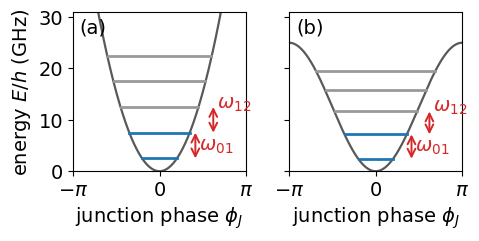

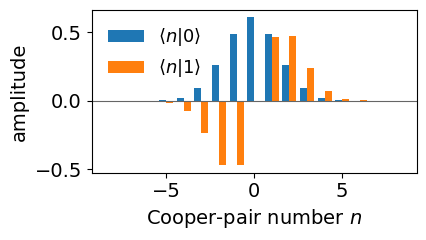

In [16]:
# transmon spectrum in the charge basis; energies as frequencies E/h in GHz, so omega/2pi = E/h
def transmon_hamiltonian(EJ, EC, ng=0.0, ncut=20):
    n = np.arange(-ncut, ncut + 1)
    H = np.diag(4 * EC * (n - ng) ** 2)                                   # charging energy, equation (33)
    H = H - EJ / 2 * (np.eye(len(n), k=1) + np.eye(len(n), k=-1))          # -E_J cos(phi_J), equation (34)
    return H, n

EC_tr = 0.25
EJ_tr = 50 * EC_tr
H_tr, n_charge = transmon_hamiltonian(EJ_tr, EC_tr)
E_tr, V_tr = np.linalg.eigh(H_tr)
f01, f12 = E_tr[1] - E_tr[0], E_tr[2] - E_tr[1]
alpha_tr = f12 - f01
f01_approx = np.sqrt(8 * EJ_tr * EC_tr) - EC_tr
print(f"E_J/E_C = {EJ_tr / EC_tr:.0f}: f01 = {f01:.3f} GHz (approximation (35): {f01_approx:.3f} GHz), "
      f"f12 = {f12:.3f} GHz, anharmonicity = {1e3 * alpha_tr:.0f} MHz (approximation: {-1e3 * EC_tr:.0f} MHz)")
assert abs(f01 - f01_approx) < 0.1 * EC_tr and abs(alpha_tr + EC_tr) < 0.2 * EC_tr

# first-order perturbation theory for the levels, measured from -E_J
w_p = np.sqrt(8 * EJ_tr * EC_tr)
E_pt = np.array([-EJ_tr + w_p * (k + 0.5) - EC_tr / 12 * (6 * k * k + 6 * k + 3) for k in range(5)])
for k in range(5):
    print(f"level {k}: exact {E_tr[k]:+.4f} GHz, first order {E_pt[k]:+.4f} GHz")
assert np.max(np.abs(E_tr[:3] - E_pt[:3])) < 0.3 * EC_tr

# the levels barely depend on the offset charge: largest change of f01 over n_g
f01_ng = [np.diff(np.linalg.eigh(transmon_hamiltonian(EJ_tr, EC_tr, ng)[0])[0][:2])[0] for ng in np.linspace(0, 0.5, 11)]
dng_khz = 1e6 * (max(f01_ng) - min(f01_ng))
print(f"change of f01 over 0 <= n_g <= 1/2: {dng_khz:.1f} kHz, {1e6 * (max(f01_ng) - min(f01_ng)) / f01:.1f} parts per million")
assert max(f01_ng) - min(f01_ng) < 1e-4

# truncation check: a larger charge basis changes nothing
E_big = np.linalg.eigh(transmon_hamiltonian(EJ_tr, EC_tr, ncut=40)[0])[0]
assert np.allclose(E_big[:6], E_tr[:6], atol=1e-10)

# charge matrix elements between eigenstates, with the eigenvector signs fixed so that n_{k,k+1} > 0
n_eig = V_tr.T @ np.diag(n_charge.astype(float)) @ V_tr
for k in range(5):
    if n_eig[k, k + 1] < 0:
        V_tr[:, k + 1] *= -1
        n_eig = V_tr.T @ np.diag(n_charge.astype(float)) @ V_tr
assert np.allclose(np.diag(n_eig)[:5], 0, atol=1e-10)                  # definite parity at n_g = 0
ratio_12_01 = n_eig[1, 2] / n_eig[0, 1]
print(f"n_01 = {n_eig[0, 1]:.3f}, n_12/n_01 = {ratio_12_01:.3f} (harmonic oscillator: sqrt(2) = {np.sqrt(2):.3f})")

NUMBERS["TrEC"] = f"{EC_tr:.2f}"
NUMBERS["TrECMHz"] = f"{1e3 * EC_tr:.0f}"
NUMBERS["TrRatio"] = f"{EJ_tr / EC_tr:.0f}"
NUMBERS["TrFOneGHz"] = f"{f01:.2f}"
NUMBERS["TrFOneApproxGHz"] = f"{f01_approx:.2f}"
NUMBERS["TrAlphaMHz"] = f"{1e3 * alpha_tr:.0f}"
NUMBERS["TrNRatio"] = f"{ratio_12_01:.2f}"
NUMBERS["TrNgKHz"] = f"{dng_khz:.0f}"

# figure 1: harmonic ladder of the LC circuit and the cosine well of the transmon
phi = np.linspace(-np.pi, np.pi, 400)
U_cos = EJ_tr * (1 - np.cos(phi))                    # junction energy, zero at the bottom
U_har = EJ_tr * phi ** 2 / 2                         # its quadratic approximation, an LC circuit
E_har = w_p * (np.arange(5) + 0.5)
E_cos = E_tr[:5] + EJ_tr                             # measured from the bottom of the well
with plt.rc_context({"font.size": 14, "axes.labelsize": 14, "legend.fontsize": 13.5}):
    fig, axs = plt.subplots(1, 2, figsize=(5.0, 2.6), sharey=True)
    for ax, U, E, lab in ((axs[0], U_har, E_har, "(a)"), (axs[1], U_cos, E_cos, "(b)")):
        ax.plot(phi, U, color="0.35", lw=1.6)
        for k, Ek in enumerate(E):
            half = phi[U <= Ek]
            ax.plot([half.min(), half.max()], [Ek, Ek], color="C0" if k < 2 else "0.6", lw=2)
        ax.set_xlim(-np.pi, np.pi); ax.set_ylim(0, 31)
        ax.set_xticks([-np.pi, 0, np.pi]); ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
        ax.set_xlabel(r"junction phase $\phi_J$")
        ax.text(0.04, 0.96, lab, transform=ax.transAxes, va="top")
        for k, x_a in enumerate((1.3, 1.95)):                 # arrow lengths are omega/2pi, since the axis is E/h
            ax.annotate("", xy=(x_a, E[k + 1]), xytext=(x_a, E[k]),
                        arrowprops=dict(arrowstyle="<->", color="C3", lw=1.4, shrinkA=0, shrinkB=0))
        ax.text(1.42, 0.5 * (E[0] + E[1]), r"$\omega_{01}$", color="C3", ha="left", va="center")
        ax.text(2.07, 0.5 * (E[1] + E[2]) + 1.2, r"$\omega_{12}$", color="C3", ha="left", va="bottom")
    axs[0].set_ylabel("energy $E/h$ (GHz)")
    fig.tight_layout()
    save(fig, "fig_lab067_transmon_levels"); plt.show()

# figure 2: the two qubit states in the charge basis
with plt.rc_context({"font.size": 14, "axes.labelsize": 14, "legend.fontsize": 13}):
    fig, ax = plt.subplots(figsize=(4.6, 2.6))
    sel = np.abs(n_charge) <= 8
    ax.bar(n_charge[sel] - 0.2, V_tr[sel, 0], width=0.4, color="C0", label=r"$\langle n|0\rangle$")
    ax.bar(n_charge[sel] + 0.2, V_tr[sel, 1], width=0.4, color="C1", label=r"$\langle n|1\rangle$")
    ax.axhline(0, color="0.4", lw=0.8)
    ax.set_xlabel("Cooper-pair number $n$"); ax.set_ylabel("amplitude")
    ax.legend(frameon=False, loc="upper left")
    fig.tight_layout()
    save(fig, "fig_lab067_transmon_charge_states"); plt.show()


In figure 1, panel (a) shows the quadratic approximation of the junction energy, an LC oscillator with equally spaced levels, and panel (b) the cosine well of the junction with the computed levels of the transmon. The two lowest levels, drawn in blue, form the qubit. In the cosine well the spacing shrinks with height, because the cosine potential rises more slowly than the parabola, and $\omega_{12}$ is smaller than $\omega_{01}$ by $|\alpha|\approx E_C$. The diagonalisation gives $\omega_{01}/2\pi=4.74$ GHz and $\alpha/2\pi=-287$ MHz, so the approximation (35), 4.75 GHz and $-250$ MHz, agrees with the exact levels to a fraction of $E_C$. Changing $n_g$ over its whole range shifts $\omega_{01}/2\pi$ by about 10 kHz, two parts in a million, so the transmon is insensitive to stray charges. Figure 2 shows the two qubit states in the charge basis. Both spread over many Cooper-pair numbers, the ground state is even in $n$ and the first excited state is odd.

A microwave line coupled through a small capacitance $C_d$ applies the voltage $V(t)=V_0\cos(\omega_dt-\phi)$ to the circuit and adds the energy $2e_0\frac{C_d}{C}V(t)\,\hat n$, so the drive couples through the charge operator. We choose the phases of the eigenstates so that the matrix elements $n_{k,k+1}$ are real and positive. At $n_g=0$ the eigenstates of the symmetric well have definite parity, so the diagonal elements $\langle k|\hat n|k\rangle$ vanish. Restricted to the two lowest levels, $\hat n\to n_{01}\hat X$, and with the zero of energy halfway between the two levels the driven transmon has the Hamiltonian $-\frac{\omega_{01}}2\hat Z+\Omega\cos(\omega_dt-\phi)\hat X$ with $\Omega=2e_0\frac{C_d}{C}V_0\,n_{01}$. It has the form of the two-level atom in a laser field. The frame rotating with the drive and the rotating-wave approximation of Section 5 therefore give $\frac\Delta2\hat Z+\frac\Omega2(\cos\phi\hat X+\sin\phi\hat Y)$ with $\Delta=\omega_d-\omega_{01}$. A resonant pulse rotates the qubit by its area, as in equation (30).

The same drive also couples $|1\rangle$ to $|2\rangle$, with the larger matrix element $n_{12}\approx\sqrt2\,n_{01}$ of an oscillator, and this transition is detuned only by $\alpha$. In the eigenbasis $\hat n$ connects mainly neighbouring levels, and in the frame rotating at $\omega_d=\omega_{01}$ the level $|k\rangle$ acquires the energy $\delta_k=E_k-E_0-k\,\omega_{01}$, so $\delta_0=\delta_1=0$ and $\delta_2=\alpha$. The rotating-wave approximation keeps these neighbour couplings and drops their counter-rotating parts,
$$\hat{\mathcal H}_{\rm RF}(t)=\sum_k\delta_k|k\rangle\langle k|+\frac{\Omega(t)}2\sum_k\frac{n_{k,k+1}}{n_{01}}\big(|k\rangle\langle k+1|+|k+1\rangle\langle k|\big) . \tag{36}$$
The simulation measures time in nanoseconds and angular frequencies in rad/ns, $\delta_k=2\pi(E_k-E_0-k\,\omega_{01})/h$. We apply Gaussian $\pi$ pulses of duration $T$ to the five lowest levels. The envelope has the standard deviation $\sigma=T/4$, is cut at $\pm2\sigma$ and shifted to vanish at the ends, and its area is $\pi$. We record the leakage, the population left in $|2\rangle$ and higher levels. The envelope has an angular spectral width of about $1/\sigma=4/T$ around $\omega_{01}$, and the pulse leaves the transition $1\to2$ unexcited once $\sigma|\alpha|\gtrsim3$, that is, for $T\gtrsim12/|\alpha|$, which is about 6.6 ns here. Predict whether a pulse of 4 ns is short or long by this criterion before running the cell.

T =    4 ns: P(|1>) = 0.6660, leakage at the end = 2.59e-01, largest leakage during the pulse = 3.47e-01
T =   20 ns: P(|1>) = 0.9956, leakage at the end = 1.50e-05, largest leakage during the pulse = 8.24e-03
12/|alpha| = 6.65 ns; final leakage first below 1e-3 at T = 8 ns (sigma |alpha| = 3.6)


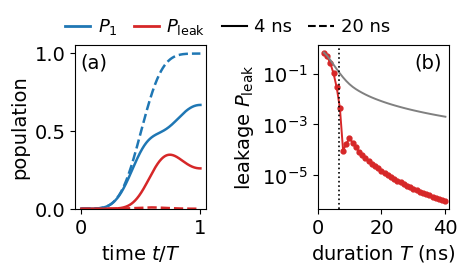

In [17]:
# leakage of a Gaussian pi pulse on the five lowest transmon levels, rotating frame (36), time in ns, rad/ns
K_tr = 5
delta_k = 2 * np.pi * np.array([(E_tr[k] - E_tr[0]) - k * f01 for k in range(K_tr)])     # rad/ns
ladder = np.diag([n_eig[k, k + 1] / n_eig[0, 1] for k in range(K_tr - 1)], 1)
ladder = ladder + ladder.T

def gaussian_pi_pulse(T, steps=600, levels=K_tr):
    # Gaussian envelope with sigma = T/4, cut at +-2 sigma and shifted to vanish at t = 0 and t = T, area pi
    t = np.linspace(0, T, steps + 1)
    tm, dt = 0.5 * (t[1:] + t[:-1]), T / steps
    g = np.exp(-(tm - T / 2) ** 2 / (2 * (T / 4) ** 2)) - np.exp(-(T / 2) ** 2 / (2 * (T / 4) ** 2))
    Om_t = np.pi * g / (g.sum() * dt)
    psi = np.zeros(levels, dtype=complex); psi[0] = 1
    pops = [np.abs(psi) ** 2]
    D_l, L_l = np.diag(delta_k[:levels]), ladder[:levels, :levels]
    for om in Om_t:
        psi = expm(-1j * dt * (D_l + om / 2 * L_l)) @ psi
        pops.append(np.abs(psi) ** 2)
    return t, np.array(pops)

# restricted to the two qubit levels, every Gaussian pulse of area pi is an exact pi rotation, equation (30)
for T in (2.0, 20.0):
    assert abs(gaussian_pi_pulse(T, levels=2)[1][-1, 1] - 1) < 1e-10

T_short, T_long = 4.0, 20.0
runs = {T: gaussian_pi_pulse(T) for T in (T_short, T_long)}
T_scan = np.arange(2.0, 41.0, 1.0)
scan = [gaussian_pi_pulse(T, steps=300)[1] for T in T_scan]
leak_end = np.array([p[-1, 2:].sum() for p in scan])
leak_max = np.array([p[:, 2:].sum(1).max() for p in scan])
for T in (T_short, T_long):
    p_end = runs[T][1][-1]
    print(f"T = {T:4.0f} ns: P(|1>) = {p_end[1]:.4f}, leakage at the end = {p_end[2:].sum():.2e}, "
          f"largest leakage during the pulse = {runs[T][1][:, 2:].sum(1).max():.2e}")
leak_short, leak_long = runs[T_short][1][-1, 2:].sum(), runs[T_long][1][-1, 2:].sum()
P1_long = runs[T_long][1][-1, 1]
T_border = 12 / (2 * np.pi * abs(alpha_tr))             # 12/|alpha| in ns (sigma |alpha| = 3), since alpha_tr is alpha/2pi in GHz
T_thr = T_scan[np.argmax(leak_end < 1e-3)]
print(f"12/|alpha| = {T_border:.2f} ns; final leakage first below 1e-3 at T = {T_thr:.0f} ns "
      f"(sigma |alpha| = {T_thr / 4 * 2 * np.pi * abs(alpha_tr):.1f})")
assert leak_short > 0.1 and leak_long < 1e-3 and leak_end[0] > leak_end[-1] and leak_max[0] > leak_max[-1]
NUMBERS["TrTShort"] = f"{T_short:.0f}"
NUMBERS["TrTLong"] = f"{T_long:.0f}"
NUMBERS["TrLeakShort"] = f"{leak_short:.2f}"
m_, e_ = f"{leak_long:.1e}".split("e")
NUMBERS["TrLeakLong"] = rf"{m_}\times10^{{{int(e_)}}}"                   # LaTeX, used in math mode
NUMBERS["TrPOneLong"] = f"{P1_long:.4f}"
NUMBERS["TrTwelveAlphaNs"] = f"{T_border:.1f}"
NUMBERS["TrTThreshNs"] = f"{T_thr:.0f}"

with plt.rc_context({"font.size": 14, "axes.labelsize": 14, "legend.fontsize": 13}):
    fig, axs = plt.subplots(1, 2, figsize=(5.0, 2.6))
    for T, ls in ((T_short, "-"), (T_long, "--")):
        t, p = runs[T]
        axs[0].plot(t / T, p[:, 1], color="C0", ls=ls, lw=1.8)
        axs[0].plot(t / T, p[:, 2:].sum(1), color="C3", ls=ls, lw=1.8)
    handles = [plt.Line2D([], [], color="C0", lw=2, label=r"$P_1$"), plt.Line2D([], [], color="C3", lw=2, label=r"$P_{\rm leak}$"),
               plt.Line2D([], [], color="k", lw=1.5, ls="-", label=f"{T_short:.0f} ns"), plt.Line2D([], [], color="k", lw=1.5, ls="--", label=f"{T_long:.0f} ns")]
    fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.09),
               handlelength=1.4, columnspacing=0.9, handletextpad=0.4)
    axs[0].set_xlabel("time $t/T$"); axs[0].set_ylabel("population")
    axs[0].set_ylim(0, 1.05)
    axs[1].semilogy(T_scan, leak_end, "o-", color="C3", lw=1.4, ms=3.5)
    axs[1].semilogy(T_scan, leak_max, "-", color="0.5", lw=1.4)
    axs[1].axvline(T_border, color="k", ls=":", lw=1.2)
    axs[1].set_xlim(0, 41); axs[1].set_xticks([0, 20, 40])
    axs[1].set_xlabel("duration $T$ (ns)"); axs[1].set_ylabel(r"leakage $P_{\rm leak}$")
    axs[0].text(0.04, 0.95, "(a)", transform=axs[0].transAxes, va="top")
    axs[1].text(0.95, 0.95, "(b)", transform=axs[1].transAxes, va="top", ha="right")
    fig.tight_layout()
    save(fig, "fig_lab067_transmon_leakage"); plt.show()


Panel (a) follows the population $P_1$ of $|1\rangle$ and the leakage $P_{\rm leak}$ during a pulse of 4 ns (solid) and of 20 ns (dashed), both of area $\pi$. The 4 ns pulse lies below the border $T\approx12/|\alpha|$ of the criterion, marked by the dotted line in panel (b), reaches the transition $1\to2$ and ends with about a quarter of the population outside the qubit. The 20 ns pulse leaves a leakage of only $1.5\times10^{-5}$, and its final $P_1=0.9956$ falls short of one because the drive also shifts the energy of $|1\rangle$ through its coupling to $|2\rangle$, so the pulse is slightly off resonance. Panel (b) shows the leakage at the end of the pulse (red dots) and its largest value during the pulse (grey line). The final leakage drops below $10^{-3}$ at about 8 ns, which is why transmon gates last tens of nanoseconds. Beyond that it does not fall monotonically, because population that has entered $|2\rangle$ can return to the qubit by the end of the pulse, and the spectral overlap of the envelope with the transition $1\to2$ oscillates with $T$. Pulses that add a quadrature component proportional to the time derivative of the envelope, called DRAG (derivative removal by adiabatic gate) pulses (F. Motzoi et al., Phys. Rev. Lett. **103**, 110501 (2009), https://doi.org/10.1103/PhysRevLett.103.110501), correct both the leakage and this level shift.

The transmon is read out through a microwave resonator, an electrical circuit with a single oscillation mode, coupled to it and detuned from its transition frequency. The resonator frequency is shifted by an amount that depends on whether the transmon is in $|0\rangle$ or $|1\rangle$, so a weak microwave tone sent through the resonator returns with a phase that reveals the state (A. Blais et al., Phys. Rev. A **69**, 062320 (2004), https://doi.org/10.1103/PhysRevA.69.062320). This dispersive readout is a measurement of $\hat Z$.

## 12. A spin-1/2 in a magnetic field

An electron carries an intrinsic angular momentum, its spin, with two possible projections on any axis, up and down. Nuclei such as the proton also have this two-valued spin, called spin-1/2. With $\hbar=1$ the spin operators are $\hat{\mathbf S}=\hat{\boldsymbol\sigma}/2$, so a spin is a two-level system from the start and needs no truncation of a larger spectrum. The spin carries the magnetic moment $\hat{\boldsymbol\mu}=\gamma\hat{\mathbf S}$, with the gyromagnetic ratio $\gamma$ of the particle, and in a magnetic field $\mathbf B$ it has the energy
$$\hat{\mathcal H}=-\gamma\,\mathbf B\cdot\hat{\mathbf S}=-\frac\gamma2\big(B_x\hat X+B_y\hat Y+B_z\hat Z\big) . \tag{37}$$
For a static field along $z$ this is $\hat{\mathcal H}=-\frac{\omega_0}2\hat Z$ with the Larmor frequency $\omega_0=\gamma B_z$, the Zeeman splitting of the two levels. We orient the $z$ axis so that $\omega_0>0$. The state $|0\rangle=|{\uparrow}\rangle$ is then the ground state, and the spin has the same Hamiltonian as the free two-level atom. For the electron $\gamma<0$, so its field points along $-z$. The electron has $|\gamma|/2\pi\approx$ 28 GHz per tesla and the proton 42.6 MHz per tesla (P. J. Mohr, D. B. Newell, B. N. Taylor and E. Tiesinga, Rev. Mod. Phys. **97**, 025002 (2025), https://doi.org/10.1103/RevModPhys.97.025002), so a field of a fraction of a tesla gives microwave frequencies for an electron and radio frequencies for a nucleus.

For a spin the Bloch vector has the components $\langle\hat\sigma_a\rangle=2\langle\hat S_a\rangle$, so it points along the mean spin, and spin up along $z$ sits at the north pole. The Schrödinger equation implies that the mean of a time-independent observable changes as $\frac{d}{dt}\langle\hat O\rangle=i\langle[\hat{\mathcal H},\hat O]\rangle$, and the commutators $[\hat S_a,\hat S_b]=i\varepsilon_{abc}\hat S_c$ give
$$\frac{d}{dt}\langle\hat{\mathbf S}\rangle=\gamma\,\langle\hat{\mathbf S}\rangle\times\mathbf B , \tag{38}$$
the equation of a magnetic moment turning about the field. In a static field $B_z$ the evolution $\hat U(t)=e^{i\omega_0t\hat Z/2}=\hat R_z(-\omega_0t)$ rotates the Bloch vector about $z$ at the angular frequency $\omega_0$, a motion called Larmor precession that runs clockwise seen from the north pole.

Before running the code, predict in which direction the Bloch vector of a spin started on the positive $x$ axis moves first.

|gamma|/2pi: electron 28.02 GHz/T, proton 42.58 MHz/T


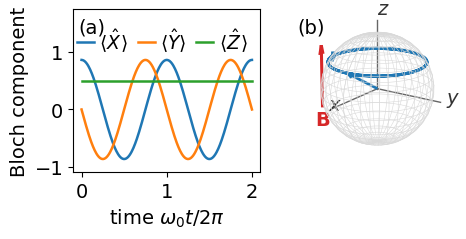

In [18]:
# Larmor precession of a spin-1/2 in a static field along z (time in units of 1/omega_0)
gamma_e = const.physical_constants["electron gyromag. ratio in MHz/T"][0]    # gamma/2pi
gamma_p = const.physical_constants["proton gyromag. ratio in MHz/T"][0]
print(f"|gamma|/2pi: electron {abs(gamma_e) / 1e3:.2f} GHz/T, proton {gamma_p:.2f} MHz/T")
NUMBERS["GammaEGHzT"] = f"{abs(gamma_e) / 1e3:.0f}"
NUMBERS["GammaPMHzT"] = f"{gamma_p:.1f}"

def bloch_axes3d(ax3):
    # unit sphere with x, y, z axes and no box, for Bloch-vector trajectories
    u, v = np.mgrid[0:2*np.pi:40j, 0:np.pi:20j]
    ax3.plot_wireframe(np.cos(u)*np.sin(v), np.sin(u)*np.sin(v), np.cos(v), color="0.85", lw=0.4)
    for vec, name in (((1.3, 0, 0), "$x$"), ((0, 1.3, 0), "$y$"), ((0, 0, 1.25), "$z$")):
        ax3.plot([0, vec[0]], [0, vec[1]], [0, vec[2]], color="0.4", lw=1)
        ax3.text(1.08 * vec[0], 1.08 * vec[1], 1.08 * vec[2], name, color="0.2")
    ax3.set_axis_off(); ax3.set_box_aspect((1, 1, 1), zoom=1.4); ax3.view_init(elev=18, azim=35)
    ax3.set_xlim(-1.2, 1.2); ax3.set_ylim(-1.2, 1.2); ax3.set_zlim(-1.2, 1.2)

def bloch_vector(psi):
    return np.array([np.vdot(psi, P @ psi).real for P in (X, Y, Z)])

w0_s = 1.0
theta0 = np.pi / 3
psi0 = np.array([np.cos(theta0 / 2), np.sin(theta0 / 2)], dtype=complex)    # Bloch vector in the x-z plane
t_l = np.linspace(0, 4 * np.pi, 300)
r_l = np.array([bloch_vector(expm(1j * w0_s * t * Z / 2) @ psi0) for t in t_l]).T
# equation (38) for B along z: the Bloch vector turns about z at -omega_0
r_pred = np.array([np.sin(theta0) * np.cos(-w0_s * t_l), np.sin(theta0) * np.sin(-w0_s * t_l), np.cos(theta0) * np.ones_like(t_l)])
assert np.allclose(r_l, r_pred, atol=1e-12)

with plt.rc_context({"font.size": 14, "axes.labelsize": 14, "legend.fontsize": 13.5}):
    fig = plt.figure(figsize=(5.0, 2.6))
    ax = fig.add_subplot(1, 2, 1)
    for k, (name, col) in enumerate(((r"$\langle\hat X\rangle$", "C0"), (r"$\langle\hat Y\rangle$", "C1"), (r"$\langle\hat Z\rangle$", "C2"))):
        ax.plot(w0_s * t_l / (2 * np.pi), r_l[k], color=col, lw=1.8, label=name)
    ax.set_xlabel(r"time $\omega_0t/2\pi$"); ax.set_ylabel("Bloch component"); ax.set_ylim(-1.1, 1.75)
    ax.legend(loc="upper right", bbox_to_anchor=(1.02, 1.0), ncol=3, frameon=False, handlelength=0.9, columnspacing=0.5, handletextpad=0.3)
    ax.text(0.03, 0.95, "(a)", transform=ax.transAxes, va="top")
    ax3 = fig.add_subplot(1, 2, 2, projection="3d")
    bloch_axes3d(ax3)
    ax3.plot(r_l[0], r_l[1], r_l[2], color="C0", lw=2.2)
    ax3.quiver(0, 0, 0, r_l[0, 0], r_l[1, 0], r_l[2, 0], color="C0", lw=2, arrow_length_ratio=0.15)
    ax3.quiver(0, -1.25, -0.6, 0, 0, 1.2, color="C3", lw=2.2, arrow_length_ratio=0.15)
    ax3.text(0, -1.25, -0.95, r"$\mathbf{B}$", color="C3", ha="center")
    k_a = 25                                           # tangent arrow shows the clockwise sense
    ax3.quiver(r_l[0, k_a], r_l[1, k_a], r_l[2, k_a], r_l[0, k_a + 6] - r_l[0, k_a], r_l[1, k_a + 6] - r_l[1, k_a], 0,
               color="C0", lw=3, arrow_length_ratio=0.6, length=0.45, normalize=True)
    ax3.text2D(0.02, 0.95, "(b)", transform=ax3.transAxes, va="top")
    fig.tight_layout()
    save(fig, "fig_lab067_spin_larmor"); plt.show()

Panel (a) shows the components of the Bloch vector of a spin started at the polar angle $\pi/3$ in the $x$–$z$ plane. The transverse components oscillate at the Larmor frequency, a quarter period apart, and $\langle\hat Z\rangle$ stays constant because the energy is conserved. Panel (b) draws the same motion on the Bloch sphere, a circle on a cone about the field $\mathbf B$, traversed clockwise seen from the north pole.

Since a static field produces only rotations about its own direction, transitions between the two levels need a transverse field. A field $B_1\cos(\omega_dt)$ along $x$, oscillating at a drive frequency $\omega_d$ close to $\omega_0$, adds to equation (37) and gives
$$\hat{\mathcal H}(t)=-\frac{\omega_0}2\hat Z+\Omega\cos(\omega_d t)\,\hat X,\qquad \Omega=-\frac{\gamma B_1}2 . \tag{39}$$
We choose the sign of $B_1$ so that $\Omega>0$, and the opposite sign only reverses the sense of the rotation. Equation (39) has the form of the two-level atom in a laser field. The oscillating field is a sum of two fields of amplitude $B_1/2$ that rotate about $z$ in opposite directions. In the frame rotating at $\omega_d$ one of them is static and the other rotates at $2\omega_d$ and averages out, which is the rotating-wave approximation. The spin then obeys the Hamiltonian $\frac\Delta2\hat Z+\frac\Omega2\hat X$ with $\Delta=\omega_d-\omega_0$, and on resonance a pulse of duration $t$ applies $\hat R_x(\Omega t)$. For $\Omega>0$ the Bloch vector leaves the north pole towards $-y$. This effect is magnetic resonance (I. I. Rabi, J. R. Zacharias, S. Millman and P. Kusch, Phys. Rev. **53**, 318 (1938), https://doi.org/10.1103/PhysRev.53.318), called electron spin resonance for electrons and nuclear magnetic resonance for nuclei. We integrate the laboratory-frame equation (39) on resonance with $\omega_0=20\,\Omega$ and compare it with the rotating-frame prediction.

omega_0/Omega = 20: largest difference of P_down from sin^2(Omega t/2) = 0.013
largest distance of the rotating-frame Bloch vector from R_x(Omega t)|0>: 0.050


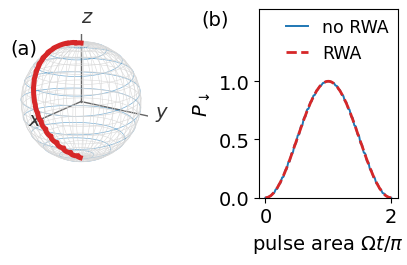

In [19]:
# magnetic resonance: resonant transverse drive in the laboratory frame, equation (39), time in units of 1/Omega
Om_s, w0_r = 1.0, 20.0
H_lab = lambda t: -w0_r / 2 * Z + Om_s * np.cos(w0_r * t) * X
T_pi = np.pi / Om_s
t_r = np.linspace(0, 2 * T_pi, 1201)
sol = solve_ivp(lambda t, y: -1j * H_lab(t) @ y, (0, t_r[-1]), np.array([1, 0], dtype=complex),
                t_eval=t_r, rtol=1e-10, atol=1e-12, method="DOP853")
r_lab = np.array([bloch_vector(sol.y[:, k]) for k in range(len(t_r))]).T
P_down = (1 - r_lab[2]) / 2
P_rwa = np.sin(Om_s * t_r / 2) ** 2
err_rwa = np.max(np.abs(P_down - P_rwa))
print(f"omega_0/Omega = {w0_r / Om_s:.0f}: largest difference of P_down from sin^2(Omega t/2) = {err_rwa:.3f}")
assert err_rwa < 0.05
# transform to the frame rotating with the drive: the Bloch vector then turns about x only
r_rot = np.array([bloch_vector(expm(-1j * w0_r * t * Z / 2) @ sol.y[:, k]) for k, t in enumerate(t_r)]).T
r_ideal = np.array([np.zeros_like(t_r), -np.sin(Om_s * t_r), np.cos(Om_s * t_r)])
print(f"largest distance of the rotating-frame Bloch vector from R_x(Omega t)|0>: {np.max(np.linalg.norm(r_rot - r_ideal, axis=0)):.3f}")
assert np.max(np.linalg.norm(r_rot - r_ideal, axis=0)) < 0.1
NUMBERS["SpinRatio"] = f"{w0_r / Om_s:.0f}"
NUMBERS["SpinRabiErr"] = f"{err_rwa:.3f}"

with plt.rc_context({"font.size": 14, "axes.labelsize": 14, "legend.fontsize": 12.5}):
    fig = plt.figure(figsize=(5.0, 2.45))
    gs = fig.add_gridspec(1, 2, width_ratios=[1.0, 1.0], wspace=0.8)
    ax3 = fig.add_subplot(gs[0], projection="3d")
    bloch_axes3d(ax3)
    ax3.set_box_aspect((1, 1, 1), zoom=1.75)
    half = t_r <= T_pi
    ax3.plot(r_lab[0, half], r_lab[1, half], r_lab[2, half], color="C0", lw=0.5, alpha=0.6)
    ax3.plot(r_rot[0, half], r_rot[1, half], r_rot[2, half], color="C3", lw=3.6, zorder=10)
    ax3.text2D(0.0, 0.97, "(a)", transform=ax3.transAxes, va="top")
    ax = fig.add_subplot(gs[1])
    ax.plot(Om_s * t_r / np.pi, P_down, color="C0", lw=1.4, label="no RWA")
    ax.plot(Om_s * t_r / np.pi, P_rwa, color="C3", lw=2.0, ls="--", label=r"RWA")
    ax.set_xlabel(r"pulse area $\Omega t/\pi$"); ax.set_ylabel(r"$P_\downarrow$")
    ax.set_ylim(0, 1.62); ax.set_yticks([0, 0.5, 1.0])
    ax.legend(loc="upper right", frameon=False, handlelength=1.3, borderaxespad=0.1)
    ax.text(-0.42, 1.0, "(b)", transform=ax.transAxes, va="top")
    save(fig, "fig_lab067_spin_rabi"); plt.show()


In panel (a) the thin blue curve is the Bloch vector in the laboratory frame during a $\pi$ pulse. It precesses fast about $z$ at $\omega_0$ while it slowly descends from the north to the south pole. The thick red curve shows the same motion in the frame rotating with the drive, a half circle about the $x$ axis through $-y$ that realises the rotation $\hat R_x(\pi)$ for $\Omega>0$. Panel (b) compares the probability $P_\downarrow$ of spin down from the laboratory-frame integration (no RWA) with the rotating-frame prediction $\sin^2(\Omega t/2)$ (RWA). The laboratory-frame curve contains small fast oscillations of order $\Omega/(4\omega_0)$, too small to see in panel (b), which are the counter-rotating terms dropped by the rotating-wave approximation.

In a semiconductor quantum dot, a nanometre-sized region that holds a single electron (D. Loss and D. P. DiVincenzo, Phys. Rev. A **57**, 120 (1998), https://doi.org/10.1103/PhysRevA.57.120), the spin is read out through the charge of the dot. The levels are tuned so that only an electron with spin down can tunnel out to a nearby reservoir. A charge sensor then records whether the electron is still there, which is a single-shot measurement of $\hat Z$ (J. M. Elzerman et al., Nature **430**, 431 (2004), https://doi.org/10.1038/nature02693). In nuclear magnetic resonance a large ensemble of spins precesses after a pulse, and its oscillating magnetisation induces a voltage in a pick-up coil (F. Bloch, Phys. Rev. **70**, 460 (1946), https://doi.org/10.1103/PhysRev.70.460). This signal measures the mean $\langle\hat X\rangle$ or $\langle\hat Y\rangle$ of the ensemble.

## 13. Exercises

1. Compute $D_{3p,1s}$ from equation (10) analytically, using $R_{31}$ from equation (5), and compare it with the matrix of Section 3.
2. Change the polarisation of the light to circular, so that it couples $m$ to $m\pm1$. Explain which orbitals with $m\neq0$ must then be added to the basis.
3. Repeat the average of Section 4 with the laser tuned to the 1s–3p transition. Identify the pair that survives and its averaged coupling.
4. Derive equation (19) from equation (18) by differentiating $b_g=a_ge^{-i\Delta t/2}$ and $b_e=a_ee^{i\Delta t/2}$.
5. Use equation (27) to predict the light shift for $\Omega=0.03$, then measure it with the one-period evolution and compare.
6. Find the laser frequency that maximises the $\pi$-pulse fidelity at $\Omega=0.04$ and compare it with the resonance shift of Section 8.
7. Diagonalise the transmon Hamiltonian (33) with $E_C/h=0.25$ GHz for $E_J/E_C$ between 1 and 100 at $n_g=0$ and $n_g=1/2$. Plot $\omega_{01}$ and $\alpha$ against $E_J/E_C$ and find the ratio above which the two offset charges give the same $\omega_{01}$ within one megahertz.
8. Repeat the leakage scan of Section 11 with $E_C/h=0.15$ GHz at fixed $\omega_{01}$ and explain the change through equation (35).
9. Drive the spin of Section 12 off resonance, $\omega_d=\omega_0+\Omega$, in the laboratory frame and compare the largest $P_\downarrow$ with the rotating-frame value $\Omega^2/(\Omega^2+\Delta^2)$.

## 14. Summary

An atom becomes a qubit through a chain of controlled approximations. The separation of the centre of mass reduces the atom to its electrons, whose energy eigenstates form a basis in which the Hamiltonian matrix is diagonal. Classical light polarised along $z$ adds off-diagonal entries only between orbitals whose angular momentum differs by one, and these entries oscillate at the laser frequency. In the interaction picture every coupling oscillates fast except the one between the two levels in resonance with the laser. The rotating-wave approximation keeps this slow coupling, and a frame rotating with the laser turns it into the constant Hamiltonian $\frac\Delta2\hat Z+\frac\Omega2(\cos\phi_L\hat X+\sin\phi_L\hat Y)$. In this Pauli language the detuning generates rotations about $z$, and a resonant pulse rotates the qubit about an axis in the $x$–$y$ plane fixed by the laser phase. Fluorescence measures $\hat Z$, and spontaneous decay is the jump $\hat S^+=|g\rangle\langle e|$. The simulation of hydrogen with ten orbitals confirms the two-level dynamics to better than one per cent at a weak field. It also measures the light shift, the Bloch–Siegert shift and the leakage, which grow with the square of the field. The excited 2p level lives only 1.6 ns, which is why atomic qubits use long-lived pairs of levels described by the same Hamiltonian.

The same qubit Hamiltonian appears in a superconducting circuit and in a spin. An LC circuit has equally spaced levels. A Josephson junction makes the transmon anharmonic, lowering $\omega_{12}$ below $\omega_{01}$ by about the charging energy. A microwave pulse longer than about $12/|\alpha|$ therefore addresses only the two lowest levels, whereas a shorter pulse leaks population into $|2\rangle$. A spin-1/2 in a magnetic field is a two-level system without truncation, and its Bloch vector is the direction of the spin. A static field makes it precess about $z$, and a resonant transverse field flips it by a rotation about an axis in the $x$–$y$ plane. In each system a resonant drive of chosen area and phase gives the rotation $\hat R_{\phi}(\theta)$. The systems differ in how the two levels are selected, how strongly the drive couples and how the state is read out.